In [1]:
import os
import re
import math
import warnings
import numpy as np
import pandas as pd
import torch

In [2]:
from transformers import pipeline

In [3]:
INPUT_FILE = "/Users/isaacasante/Paper3_data.csv"

In [4]:
OUTPUT_DIR = "paper3_full_workflow_outputs"

In [5]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [6]:
INPUT_TYPE = "csv"

In [7]:
SENTIMENT_EWOM_MODEL = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

In [8]:
SENTIMENT_LABEL_MAP = {
    "LABEL_0": -1.0,   # negative
    "LABEL_1": 0.0,    # neutral
    "LABEL_2": 1.0     # positive
}

In [9]:
CHUNK_SIZE = 1000
BATCH_SIZE = 16
MAX_LENGTH = 256

In [10]:
VALIDATION_SAMPLE_SIZE = 400

In [11]:
RANDOM_STATE = 42

In [12]:
if INPUT_TYPE.lower() == "csv":
    df = pd.read_csv(INPUT_FILE)
elif INPUT_TYPE.lower() == "excel":
    df = pd.read_excel(INPUT_FILE)
else:
    raise ValueError("INPUT_TYPE must be 'csv' or 'excel'")

print("Raw shape:", df.shape)

Raw shape: (30005, 21)


In [13]:
keep_cols = [
    "医生性别", "医生职称", "标注部门名称", "所在省份", "所在城市",
    "医生标识", "评价数量", "患者数量", "评论标识", "评论时间",
    "评论内容", "评论类型", "评论症状", "评论标签", "评论打分"
]

In [14]:
missing_cols = [c for c in keep_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df = df[keep_cols].copy()

In [15]:
df = df.rename(columns={
    "医生性别": "doctor_gender",
    "医生职称": "doctor_title",
    "标注部门名称": "department",
    "所在省份": "province",
    "所在城市": "city",
    "医生标识": "doctor_raw_id",
    "评价数量": "review_count",
    "患者数量": "patient_count",
    "评论标识": "review_raw_id",
    "评论时间": "review_time",
    "评论内容": "review_text",
    "评论类型": "review_type",
    "评论症状": "review_symptom",
    "评论标签": "review_tags",
    "评论打分": "rating"
})

In [16]:
def clean_text_basic(x):
    if pd.isna(x):
        return np.nan
    x = str(x)
    x = x.replace("\u000b", " ")   # weird invisible symbol
    x = x.replace("\xa0", " ")
    x = re.sub(r"\s+", " ", x).strip()
    if x in ["", "nan", "None", "null", "NULL"]:
        return np.nan
    return x

In [17]:
for col in ["doctor_gender", "doctor_title", "department", "province", "city",
            "review_text", "review_type", "review_symptom", "review_tags"]:
    df[col] = df[col].apply(clean_text_basic)

In [18]:
for col in ["review_count", "patient_count", "rating"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [19]:
df["review_time"] = pd.to_datetime(df["review_time"], errors="coerce")

In [20]:
doctor_map = {
    k: f"D{i:06d}" for i, k in enumerate(df["doctor_raw_id"].dropna().astype(str).unique(), start=1)
}

In [21]:
review_map = {
    k: f"R{i:06d}" for i, k in enumerate(df["review_raw_id"].dropna().astype(str).unique(), start=1)
}

In [22]:
df["doctor_id"] = df["doctor_raw_id"].astype(str).map(doctor_map)

In [23]:
df["review_id"] = df["review_raw_id"].astype(str).map(review_map)

In [24]:
df = df.drop(columns=["doctor_raw_id", "review_raw_id"])

In [25]:
def deidentify_text(text):
    if pd.isna(text):
        return text
    text = str(text)

    # phone
    text = re.sub(r'1[3-9]\d{9}', '[PHONE]', text)

    # email
    text = re.sub(r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}', '[EMAIL]', text)

    # URL
    text = re.sub(r'http[s]?://\S+|www\.\S+', '[URL]', text)

    # hospital-like names
    text = re.sub(r'[\u4e00-\u9fffA-Za-z0-9]+医院', '[HOSPITAL]', text)

    return text

In [26]:
df["review_text"] = df["review_text"].apply(deidentify_text)

In [27]:
df["doctor_gender"] = df["doctor_gender"].replace({
    "男 ": "男",
    "女 ": "女",
    "male": "男",
    "female": "女",
    "Male": "男",
    "Female": "女"
})

In [28]:
def normalize_title(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    return x

In [29]:
df["doctor_title"] = df["doctor_title"].apply(normalize_title)

In [30]:
def title_to_num(x):
    if pd.isna(x):
        return np.nan
    x = str(x)
    if "主任医师" in x and "副" not in x:
        return 4
    if "副主任医师" in x:
        return 3
    if "主治医师" in x:
        return 2
    if "住院医师" in x:
        return 1
    return np.nan

In [31]:
df["doctor_title_num"] = df["doctor_title"].apply(title_to_num)

In [32]:
for col in ["department", "province", "city", "review_type"]:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace("nan", np.nan)

In [33]:
df["review_year"] = df["review_time"].dt.year
df["review_month"] = df["review_time"].dt.month
df["review_quarter"] = df["review_time"].dt.quarter

In [34]:
before_dup = len(df)

In [35]:
df = df.drop_duplicates(subset=["review_id"])

In [36]:
after_dup = len(df)

In [37]:
print("Duplicates removed:", before_dup - after_dup)

Duplicates removed: 0


In [38]:
df["review_text"] = df["review_text"].fillna("").astype(str).str.strip()

In [39]:
df["review_tags"] = df["review_tags"].fillna("").astype(str).str.strip()

In [40]:
df["review_symptom"] = df["review_symptom"].fillna("").astype(str).str.strip()

In [41]:
df["review_length"] = df["review_text"].str.len()

In [42]:
df = df[df["rating"].notna()].copy()

In [43]:
df = df[(df["review_length"] > 0) | (df["review_tags"].str.len() > 0)].copy()

In [44]:
print("Shape after usability filter:", df.shape)

Shape after usability filter: (30005, 20)


In [45]:
def split_tags(x):
    if pd.isna(x) or str(x).strip() == "":
        return []
    parts = re.split(r"[、，,；;|/]+", str(x))
    return [p.strip() for p in parts if p.strip()]

In [46]:
df["tag_list"] = df["review_tags"].apply(split_tags)
df["tag_count"] = df["tag_list"].apply(len)
df["symptom_present"] = (df["review_symptom"].str.len() > 0).astype(int)

In [47]:
df["log_review_count"] = np.log1p(df["review_count"].clip(lower=0))
df["log_patient_count"] = np.log1p(df["patient_count"].clip(lower=0))

In [48]:
complaint_keywords = [
    "不满意", "态度不好", "态度一般", "态度差", "态度很差", "较差",
    "没耐心", "没有耐心", "不负责", "较不负责", "不专业", "较不专业",
    "没帮助", "没有帮助", "较没帮助", "回复慢", "回复较慢", "回复太慢",
    "不回复", "没回复", "答非所问", "缺少解释", "没有解释", "惜字如金",
    "只回一句", "没有实质性帮助", "没有有用的信息", "完全没意义", "不满"
]

In [49]:
gratitude_keywords = [
    "谢谢", "感谢", "感激", "很耐心", "非常耐心", "耐心",
    "很负责", "负责", "很专业", "专业", "帮助很大", "有帮助",
    "回复及时", "讲解清楚", "解释清楚", "认真", "细心", "非常满意", "满意", "好多了"
]

In [50]:
negative_tag_keywords = [
    "态度较差", "态度很差", "没有耐心", "较不负责", "较没帮助",
    "回复较慢", "回复太慢", "较不专业", "缺少解释", "答非所问", "没有帮助"
]

In [51]:
positive_tag_keywords = [
    "耐心负责", "非常满意", "回复及时", "很专业", "帮助很大", "态度很好"
]

In [52]:
def contains_any(text, keywords):
    if pd.isna(text):
        return False
    return any(k in str(text) for k in keywords)

In [53]:
df["complaint_text"] = df["review_text"].apply(lambda x: int(contains_any(x, complaint_keywords)))

In [54]:
df["gratitude_text"] = df["review_text"].apply(lambda x: int(contains_any(x, gratitude_keywords)))

In [55]:
df["complaint_tags"] = df["tag_list"].apply(lambda x: int(any(t in negative_tag_keywords for t in x)))

In [56]:
df["gratitude_tags"] = df["tag_list"].apply(lambda x: int(any(t in positive_tag_keywords for t in x)))

In [57]:
df["complaint_present"] = ((df["complaint_text"] == 1) | (df["complaint_tags"] == 1)).astype(int)

In [58]:
df["gratitude_present"] = ((df["gratitude_text"] == 1) | (df["gratitude_tags"] == 1)).astype(int)

In [59]:
detail_keywords = [
    "检查", "化验", "报告", "片子", "单子", "诊断", "解释", "讲解", "建议", "方案",
    "用药", "药", "复查", "治疗", "处方", "追问", "咨询", "多久", "怎么", "能不能",
    "回复", "问题", "开单子", "说明书", "医院", "孩子", "上学"
]

In [60]:
boilerplate_texts = [
    "患者对本次服务感觉非常不满意",
    "患者对本次服务感觉不满意",
    "不满意"
]

In [61]:
def count_keywords(text, keywords):
    if pd.isna(text):
        return 0
    return sum(1 for k in keywords if k in str(text))

In [62]:
df["detail_keyword_count"] = df["review_text"].apply(lambda x: count_keywords(x, detail_keywords))

In [63]:
df["question_mark_count"] = df["review_text"].apply(lambda x: str(x).count("?") + str(x).count("？"))

In [64]:
df["boilerplate_flag"] = df["review_text"].apply(lambda x: int(str(x).strip() in boilerplate_texts))

In [65]:
def zscore_safe(s):
    s = pd.to_numeric(s, errors="coerce")
    std = s.std(ddof=0)
    if pd.isna(std) or std == 0:
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.mean()) / std

In [66]:
df["z_review_length"] = zscore_safe(df["review_length"])

In [67]:
df["z_detail_keyword_count"] = zscore_safe(df["detail_keyword_count"])

In [68]:
df["z_tag_count"] = zscore_safe(df["tag_count"])

In [69]:
df["z_question_mark_count"] = zscore_safe(df["question_mark_count"])

In [70]:
df["informativeness_raw"] = (
    0.45 * df["z_review_length"].fillna(0) +
    0.30 * df["z_detail_keyword_count"].fillna(0) +
    0.10 * df["symptom_present"].fillna(0) +
    0.10 * df["z_tag_count"].fillna(0) +
    0.05 * df["z_question_mark_count"].fillna(0) -
    0.40 * df["boilerplate_flag"].fillna(0)
)

In [71]:
df["informativeness"] = zscore_safe(df["informativeness_raw"])

In [72]:
clean_base_path = os.path.join(OUTPUT_DIR, "paper3_clean_base.csv")
df.to_csv(clean_base_path, index=False, encoding="utf-8-sig")
print("Saved clean base file:", clean_base_path)

Saved clean base file: paper3_full_workflow_outputs/paper3_clean_base.csv


In [73]:
sentiment_input = df[["review_id", "review_text"]].copy()
sentiment_input["review_text"] = sentiment_input["review_text"].fillna("").astype(str).str.strip()
sentiment_input = sentiment_input[sentiment_input["review_text"].str.len() > 0].copy()
sentiment_input = sentiment_input.reset_index(drop=True)

print("Running sentiment model on", len(sentiment_input), "reviews...")

Running sentiment model on 30005 reviews...


In [74]:
!pip uninstall -y protobuf sentencepiece

In [75]:
import sys
print(sys.executable)

/Users/isaacasante/opt/anaconda3/envs/paper3_nlp/bin/python


In [76]:
import sys
!{/Users/isaacasante/opt/anaconda3/envs/paper3_nlp/bin/python} -m pip show protobuf
!{/Users/isaacasante/opt/anaconda3/envs/paper3_nlp/bin/python} -m pip show sentencepiece

zsh:1: parse error near `-m'
zsh:1: parse error near `-m'


In [77]:
import sys
print(sys.executable)

/Users/isaacasante/opt/anaconda3/envs/paper3_nlp/bin/python


In [78]:
import sys
import subprocess

subprocess.run([sys.executable, "-m", "pip", "show", "protobuf"])
subprocess.run([sys.executable, "-m", "pip", "show", "sentencepiece"])

Name: protobuf
Version: 3.20.3
Summary: Protocol Buffers
Home-page: https://developers.google.com/protocol-buffers/
Author: 
Author-email: 
License: BSD-3-Clause
Location: /Users/isaacasante/opt/anaconda3/envs/paper3_nlp/lib/python3.10/site-packages
Requires: 
Required-by: 
Name: sentencepiece
Version: 0.2.1
Summary: Unsupervised text tokenizer and detokenizer.
Home-page: https://github.com/google/sentencepiece
Author: 
Author-email: Taku Kudo <taku@google.com>
License: 
Location: /Users/isaacasante/opt/anaconda3/envs/paper3_nlp/lib/python3.10/site-packages
Requires: 
Required-by: 


CompletedProcess(args=['/Users/isaacasante/opt/anaconda3/envs/paper3_nlp/bin/python', '-m', 'pip', 'show', 'sentencepiece'], returncode=0)

In [79]:
import sys
import subprocess

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--upgrade", "--force-reinstall",
    "protobuf==3.20.3", "sentencepiece"
])

  Using cached protobuf-3.20.3-py2.py3-none-any.whl.metadata (720 bytes)
  Using cached sentencepiece-0.2.1-cp310-cp310-macosx_10_9_x86_64.whl.metadata (10 kB)
Using cached protobuf-3.20.3-py2.py3-none-any.whl (162 kB)
Using cached sentencepiece-0.2.1-cp310-cp310-macosx_10_9_x86_64.whl (1.3 MB)
  Attempting uninstall: sentencepiece
    Found existing installation: sentencepiece 0.2.1
    Uninstalling sentencepiece-0.2.1:
      Successfully uninstalled sentencepiece-0.2.1
  Attempting uninstall: protobuf
    Found existing installation: protobuf 3.20.3
    Uninstalling protobuf-3.20.3:
      Successfully uninstalled protobuf-3.20.3╺━━━━━━━━━━━━━━━━━━━ 1/2 [protobuf]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [protobuf]0m 1/2 [protobuf]


CompletedProcess(args=['/Users/isaacasante/opt/anaconda3/envs/paper3_nlp/bin/python', '-m', 'pip', 'install', '--upgrade', '--force-reinstall', 'protobuf==3.20.3', 'sentencepiece'], returncode=0)

In [80]:
import google.protobuf
import sentencepiece
import torch
import transformers
from transformers import pipeline

In [83]:
print("Imports OK")
print("sentencepiece:", sentencepiece.__version__)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

Imports OK
sentencepiece: 0.2.1
torch: 2.6.0
transformers: 4.49.0


In [84]:
SENTIMENT_EWOM_MODEL = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
MAX_LENGTH = 256

clf = pipeline(
    "text-classification",
    model=SENTIMENT_EWOM_MODEL,
    tokenizer=SENTIMENT_EWOM_MODEL,
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH,
    top_k=1,
    device=-1
)

Device set to use cpu


In [85]:
print(clf([
    "医生很耐心，解释很清楚。",
    "回复很慢，没有帮助。"
]))

[[{'label': 'positive', 'score': 0.6261844635009766}], [{'label': 'negative', 'score': 0.9040839672088623}]]


In [86]:
all_chunks = []

In [87]:
n_chunks = math.ceil(len(sentiment_input) / CHUNK_SIZE)

In [88]:
for chunk_idx in range(n_chunks):
    start = chunk_idx * CHUNK_SIZE
    end = min((chunk_idx + 1) * CHUNK_SIZE, len(sentiment_input))
    chunk = sentiment_input.iloc[start:end].copy()

    texts = chunk["review_text"].tolist()
    results = []

    for i in range(0, len(texts), BATCH_SIZE):
        batch_texts = texts[i:i+BATCH_SIZE]
        preds = clf(batch_texts)

        for pred in preds:
            best = pred[0] if isinstance(pred, list) else pred
            label = best["label"]
            score = float(best["score"])
            polarity = SENTIMENT_LABEL_MAP.get(label, np.nan)

            results.append({
                "sentiment_label_raw": label,
                "sentiment_score_raw": score,
                "sentiment_polarity": polarity
            })

    result_df = pd.DataFrame(results)
    out_chunk = pd.concat([chunk.reset_index(drop=True), result_df], axis=1)
    all_chunks.append(out_chunk)

    print(f"Finished chunk {chunk_idx + 1}/{n_chunks}")

Finished chunk 1/31
Finished chunk 2/31
Finished chunk 3/31
Finished chunk 4/31
Finished chunk 5/31
Finished chunk 6/31
Finished chunk 7/31
Finished chunk 8/31
Finished chunk 9/31
Finished chunk 10/31
Finished chunk 11/31
Finished chunk 12/31
Finished chunk 13/31
Finished chunk 14/31
Finished chunk 15/31
Finished chunk 16/31
Finished chunk 17/31
Finished chunk 18/31
Finished chunk 19/31
Finished chunk 20/31
Finished chunk 21/31
Finished chunk 22/31
Finished chunk 23/31
Finished chunk 24/31
Finished chunk 25/31
Finished chunk 26/31
Finished chunk 27/31
Finished chunk 28/31
Finished chunk 29/31
Finished chunk 30/31
Finished chunk 31/31


In [89]:
sentiment_df = pd.concat(all_chunks, axis=0).reset_index(drop=True)

In [90]:
df = df.merge(
    sentiment_df[["review_id", "sentiment_label_raw", "sentiment_score_raw", "sentiment_polarity"]],
    on="review_id",
    how="left"
)

In [91]:
df["sentiment_continuous"] = df["sentiment_polarity"]

In [109]:
sentiment_path = os.path.join(OUTPUT_DIR, "paper3_sentiment_scored.csv")
df.to_csv(sentiment_path, index=False, encoding="utf-8-sig")
print("Saved sentiment-scored file:", sentiment_path)

Saved sentiment-scored file: paper3_full_workflow_outputs/paper3_sentiment_scored.csv


In [110]:
summary = {
    "n_reviews": len(df),
    "n_unique_doctors": df["doctor_id"].nunique(),
    "n_departments": df["department"].nunique(dropna=True),
    "n_provinces": df["province"].nunique(dropna=True),
    "n_cities": df["city"].nunique(dropna=True),
    "rating_mean": df["rating"].mean(),
    "rating_std": df["rating"].std(),
    "review_length_mean": df["review_length"].mean(),
    "complaint_share": df["complaint_present"].mean(),
    "gratitude_share": df["gratitude_present"].mean(),
    "time_min": df["review_time"].min(),
    "time_max": df["review_time"].max()
}

In [111]:
summary_df = pd.DataFrame([summary])
summary_path = os.path.join(OUTPUT_DIR, "descriptive_summary.csv")
summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")

In [112]:
def stratified_validation_sample(data, n=400, random_state=42):
    if "rating" not in data.columns or data["rating"].notna().sum() == 0:
        return data.sample(min(n, len(data)), random_state=random_state)

    sampled_parts = []
    group_sizes = data["rating"].value_counts(dropna=False)
    total = len(data)

    alloc = (group_sizes / total * n).round().astype(int)
    alloc[alloc == 0] = 1

    diff = n - alloc.sum()
    groups = alloc.index.tolist()

    idx = 0
    while diff != 0 and len(groups) > 0:
        g = groups[idx % len(groups)]
        if diff > 0:
            alloc[g] += 1
            diff -= 1
        else:
            if alloc[g] > 1:
                alloc[g] -= 1
                diff += 1
        idx += 1

    for rating_val, take_n in alloc.items():
        g = data[data["rating"] == rating_val]
        take_n = min(take_n, len(g))
        if take_n > 0:
            sampled_parts.append(g.sample(n=take_n, random_state=random_state))

    out = pd.concat(sampled_parts, axis=0).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return out.head(n)

In [113]:
validation_cols = [
    "review_id", "doctor_id", "rating", "review_time", "review_text", "review_tags", "review_symptom",
    "sentiment_label_raw", "sentiment_score_raw", "sentiment_continuous",
    "complaint_present", "gratitude_present", "informativeness"
]

In [97]:
validation_df = stratified_validation_sample(df[validation_cols].copy(), n=VALIDATION_SAMPLE_SIZE, random_state=RANDOM_STATE)

In [114]:
validation_df["human_sentiment"] = np.nan
validation_df["human_complaint"] = np.nan
validation_df["human_gratitude"] = np.nan
validation_df["human_informativeness_1to5"] = np.nan
validation_df["coder_id"] = np.nan
validation_df["notes"] = np.nan

In [115]:
validation_path = os.path.join(OUTPUT_DIR, "paper3_validation_sample.csv")
validation_df.to_csv(validation_path, index=False, encoding="utf-8-sig")

In [116]:
model_cols = [
    "review_id", "doctor_id",
    "doctor_gender", "doctor_title", "doctor_title_num",
    "department", "province", "city",
    "review_count", "patient_count", "log_review_count", "log_patient_count",
    "review_time", "review_year", "review_month", "review_quarter",
    "review_type", "review_symptom", "review_tags", "review_text",
    "rating",
    "review_length", "tag_count", "symptom_present",
    "complaint_present", "gratitude_present",
    "detail_keyword_count", "question_mark_count",
    "informativeness",
    "sentiment_label_raw", "sentiment_score_raw", "sentiment_continuous"
]

In [117]:
model_df = df[model_cols].copy()

In [118]:
model_path = os.path.join(OUTPUT_DIR, "paper3_model_ready.csv")
model_df.to_csv(model_path, index=False, encoding="utf-8-sig")

In [119]:
print("Saved model-ready file:", model_path)
print("Saved validation sample:", validation_path)
print("Saved descriptive summary:", summary_path)
print("Workflow completed.")

Saved model-ready file: paper3_full_workflow_outputs/paper3_model_ready.csv
Saved validation sample: paper3_full_workflow_outputs/paper3_validation_sample.csv
Saved descriptive summary: paper3_full_workflow_outputs/descriptive_summary.csv
Workflow completed.


In [120]:
print(df[["sentiment_label_raw", "sentiment_score_raw", "sentiment_polarity", "sentiment_continuous"]].head(10))
print(df[["sentiment_label_raw", "sentiment_score_raw", "sentiment_polarity", "sentiment_continuous"]].isna().mean())

  sentiment_label_raw  sentiment_score_raw  sentiment_polarity  \
0            negative             0.761023                 NaN   
1            negative             0.435806                 NaN   
2             neutral             0.436635                 NaN   
3            negative             0.755766                 NaN   
4            negative             0.544904                 NaN   
5            negative             0.816104                 NaN   
6            negative             0.534556                 NaN   
7            negative             0.517508                 NaN   
8            negative             0.561772                 NaN   
9            negative             0.830801                 NaN   

   sentiment_continuous  
0                   NaN  
1                   NaN  
2                   NaN  
3                   NaN  
4                   NaN  
5                   NaN  
6                   NaN  
7                   NaN  
8                   NaN  
9            

In [121]:
SENTIMENT_LABEL_MAP = {
    "negative": -1.0,
    "neutral": 0.0,
    "positive": 1.0
}

In [122]:
import pandas as pd
import numpy as np

In [123]:
file_path = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready.csv"
df = pd.read_csv(file_path)

label_map = {
    "negative": -1.0,
    "neutral": 0.0,
    "positive": 1.0
}

In [124]:
df["sentiment_label_raw"] = df["sentiment_label_raw"].astype(str).str.strip().str.lower()
df["sentiment_continuous"] = df["sentiment_label_raw"].map(label_map)

In [125]:
print(df["sentiment_label_raw"].value_counts(dropna=False))
print(df["sentiment_continuous"].isna().mean())

sentiment_label_raw
positive    24998
negative     2837
neutral      2170
Name: count, dtype: int64
0.0


In [126]:
df.to_csv(file_path, index=False, encoding="utf-8-sig")
print("Updated file saved.")

Updated file saved.


In [127]:
df["sentiment_label_raw"] = df["sentiment_label_raw"].astype(str).str.strip().str.lower()
df["sentiment_polarity"] = df["sentiment_label_raw"].map(label_map)
df["sentiment_continuous"] = df["sentiment_polarity"]

In [128]:
print(df[["sentiment_label_raw", "sentiment_polarity", "sentiment_continuous"]].head())
print(df["sentiment_continuous"].isna().mean())

  sentiment_label_raw  sentiment_polarity  sentiment_continuous
0            negative                -1.0                  -1.0
1            negative                -1.0                  -1.0
2             neutral                 0.0                   0.0
3            negative                -1.0                  -1.0
4            negative                -1.0                  -1.0
0.0


In [131]:
df.to_csv(file_path, index=False, encoding="utf-8-sig")
print("Updated file saved.")

Updated file saved.


In [130]:
print(df[["sentiment_label_raw", "sentiment_continuous"]].head(10))
print(df["sentiment_continuous"].value_counts(dropna=False))

  sentiment_label_raw  sentiment_continuous
0            negative                  -1.0
1            negative                  -1.0
2             neutral                   0.0
3            negative                  -1.0
4            negative                  -1.0
5            negative                  -1.0
6            negative                  -1.0
7            negative                  -1.0
8            negative                  -1.0
9            negative                  -1.0
sentiment_continuous
 1.0    24998
-1.0     2837
 0.0     2170
Name: count, dtype: int64


In [132]:
import pandas as pd
import numpy as np

In [133]:
sentiment_scored_path = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_sentiment_scored.csv"
model_ready_path = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready.csv"
validation_sample_path = "/Users/isaacasante/paper3_full_workflow_outputs/paper1_validation_sample.csv"
descriptive_summary_path = "/Users/isaacasante/paper3_full_workflow_outputs/descriptive_summary.csv"

In [134]:
sentiment_scored_v2_path = "paper3_full_workflow_outputs/paper3_sentiment_scored_v2.csv"
model_ready_v2_path = "paper3_full_workflow_outputs/paper3_model_ready_v2.csv"
validation_sample_v2_path = "paper3_full_workflow_outputs/paper3_validation_sample_v2.csv"
descriptive_summary_v2_path = "paper3_full_workflow_outputs/paper3_descriptive_summary_v2.csv"

In [135]:
label_map = {
    "negative": -1.0,
    "neutral": 0.0,
    "positive": 1.0
}

In [136]:
sent_df = pd.read_csv(sentiment_scored_path)

In [137]:
sent_df["sentiment_label_raw"] = sent_df["sentiment_label_raw"].astype(str).str.strip().str.lower()
sent_df["sentiment_polarity"] = sent_df["sentiment_label_raw"].map(label_map)
sent_df["sentiment_continuous"] = sent_df["sentiment_polarity"]

In [138]:
sent_df.to_csv(sentiment_scored_v2_path, index=False, encoding="utf-8-sig")
print("Saved:", sentiment_scored_v2_path)

Saved: paper3_full_workflow_outputs/paper3_sentiment_scored_v2.csv


In [139]:
model_df = pd.read_csv(model_ready_path)

In [140]:
model_df["sentiment_label_raw"] = model_df["sentiment_label_raw"].astype(str).str.strip().str.lower()
model_df["sentiment_polarity"] = model_df["sentiment_label_raw"].map(label_map)
model_df["sentiment_continuous"] = model_df["sentiment_polarity"]

In [141]:
model_df.to_csv(model_ready_v2_path, index=False, encoding="utf-8-sig")
print("Saved:", model_ready_v2_path)

Saved: paper3_full_workflow_outputs/paper3_model_ready_v2.csv


In [142]:
VALIDATION_SAMPLE_SIZE = 400
RANDOM_STATE = 42

In [143]:
def stratified_validation_sample(data, n=400, random_state=42):
    if "rating" not in data.columns or data["rating"].notna().sum() == 0:
        return data.sample(min(n, len(data)), random_state=random_state)

    sampled_parts = []
    group_sizes = data["rating"].value_counts(dropna=False)
    total = len(data)

    alloc = (group_sizes / total * n).round().astype(int)
    alloc[alloc == 0] = 1

    diff = n - alloc.sum()
    groups = alloc.index.tolist()

    idx = 0
    while diff != 0 and len(groups) > 0:
        g = groups[idx % len(groups)]
        if diff > 0:
            alloc[g] += 1
            diff -= 1
        else:
            if alloc[g] > 1:
                alloc[g] -= 1
                diff += 1
        idx += 1

    for rating_val, take_n in alloc.items():
        g = data[data["rating"] == rating_val]
        take_n = min(take_n, len(g))
        if take_n > 0:
            sampled_parts.append(g.sample(n=take_n, random_state=random_state))

    out = pd.concat(sampled_parts, axis=0).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return out.head(n)

In [144]:
validation_cols = [
    "review_id", "doctor_id", "rating", "review_time", "review_text", "review_tags", "review_symptom",
    "sentiment_label_raw", "sentiment_score_raw", "sentiment_continuous",
    "complaint_present", "gratitude_present", "informativeness"
]

In [145]:
validation_df = stratified_validation_sample(
    model_df[validation_cols].copy(),
    n=VALIDATION_SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

In [146]:
validation_df["human_sentiment"] = np.nan
validation_df["human_complaint"] = np.nan
validation_df["human_gratitude"] = np.nan
validation_df["human_informativeness_1to5"] = np.nan
validation_df["coder_id"] = np.nan
validation_df["notes"] = np.nan

In [147]:
validation_df.to_csv(validation_sample_v2_path, index=False, encoding="utf-8-sig")
print("Saved:", validation_sample_v2_path)

Saved: paper3_full_workflow_outputs/paper3_validation_sample_v2.csv


In [148]:
summary = {
    "n_reviews": len(model_df),
    "n_unique_doctors": model_df["doctor_id"].nunique(),
    "n_departments": model_df["department"].nunique(dropna=True) if "department" in model_df.columns else np.nan,
    "n_provinces": model_df["province"].nunique(dropna=True) if "province" in model_df.columns else np.nan,
    "n_cities": model_df["city"].nunique(dropna=True) if "city" in model_df.columns else np.nan,
    "rating_mean": model_df["rating"].mean() if "rating" in model_df.columns else np.nan,
    "rating_std": model_df["rating"].std() if "rating" in model_df.columns else np.nan,
    "review_length_mean": model_df["review_length"].mean() if "review_length" in model_df.columns else np.nan,
    "complaint_share": model_df["complaint_present"].mean() if "complaint_present" in model_df.columns else np.nan,
    "gratitude_share": model_df["gratitude_present"].mean() if "gratitude_present" in model_df.columns else np.nan,
    "sentiment_mean": model_df["sentiment_continuous"].mean() if "sentiment_continuous" in model_df.columns else np.nan,
    "sentiment_std": model_df["sentiment_continuous"].std() if "sentiment_continuous" in model_df.columns else np.nan,
    "time_min": model_df["review_time"].min() if "review_time" in model_df.columns else np.nan,
    "time_max": model_df["review_time"].max() if "review_time" in model_df.columns else np.nan
}

In [149]:
summary_df = pd.DataFrame([summary])
summary_df.to_csv(descriptive_summary_v2_path, index=False, encoding="utf-8-sig")
print("Saved:", descriptive_summary_v2_path)

Saved: paper3_full_workflow_outputs/paper3_descriptive_summary_v2.csv


In [150]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'matplotlib'

In [151]:
!pip install matplotlib

In [152]:
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'matplotlib'

In [153]:
conda install matplotlib

Retrieving notices: ...working... done
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 23.9.0
  latest version: 25.7.0

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize the number of packages updated during conda update use

     conda install conda=25.7.0



## Package Plan ##

  environment location: /Users/isaacasante/opt/anaconda3/envs/paper3_nlp

  added / updated specs:
    - matplotlib


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    aom-3.6.0                  |       hcec6c5f_0         3.0 MB
    brotli-python-1.0.9        |  py310h6d0c2b6_9         384 KB
    cairo-1.16.0               |       h08824b9_6         1.0 MB
    contourpy-1.3.1            |  py310h1962661_0         255 KB
    dav1d-1.2.1                |       h6c40b1e_0         732 KB
    fontconfig-2.14.1          |       h

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"
OUTPUT_DIR = "paper3_descriptives"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
FREQ_DIR = os.path.join(OUTPUT_DIR, "paper3_frequency_tables")
HIST_DIR = os.path.join(OUTPUT_DIR, "paper3_histograms")
os.makedirs(FREQ_DIR, exist_ok=True)
os.makedirs(HIST_DIR, exist_ok=True)

In [4]:
df = pd.read_csv(INPUT_FILE)

In [5]:
print("Data shape:", df.shape)
print(df.columns.tolist())

Data shape: (30005, 33)
['review_id', 'doctor_id', 'doctor_gender', 'doctor_title', 'doctor_title_num', 'department', 'province', 'city', 'review_count', 'patient_count', 'log_review_count', 'log_patient_count', 'review_time', 'review_year', 'review_month', 'review_quarter', 'review_type', 'review_symptom', 'review_tags', 'review_text', 'rating', 'review_length', 'tag_count', 'symptom_present', 'complaint_present', 'gratitude_present', 'detail_keyword_count', 'question_mark_count', 'informativeness', 'sentiment_label_raw', 'sentiment_score_raw', 'sentiment_continuous', 'sentiment_polarity']


In [6]:
categorical_vars = [
    "doctor_gender",
    "doctor_title",
    "doctor_title_num",
    "department",
    "province",
    "city",
    "review_type",
    "complaint_present",
    "gratitude_present",
    "symptom_present",
    "sentiment_label_raw"
]

In [7]:
for var in categorical_vars:
    if var in df.columns:
        freq = df[var].value_counts(dropna=False).reset_index()
        freq.columns = [var, "count"]
        freq["percent"] = (freq["count"] / len(df) * 100).round(2)
        freq.to_csv(
            os.path.join(FREQ_DIR, f"{var}_frequency.csv"),
            index=False,
            encoding="utf-8-sig"
        )
        print(f"Saved frequency table for: {var}")

Saved frequency table for: doctor_gender
Saved frequency table for: doctor_title
Saved frequency table for: doctor_title_num
Saved frequency table for: department
Saved frequency table for: province
Saved frequency table for: city
Saved frequency table for: review_type
Saved frequency table for: complaint_present
Saved frequency table for: gratitude_present
Saved frequency table for: symptom_present
Saved frequency table for: sentiment_label_raw


In [8]:
numeric_vars = [
    "rating",
    "sentiment_continuous",
    "informativeness",
    "review_length",
    "tag_count",
    "review_count",
    "patient_count",
    "log_review_count",
    "log_patient_count",
    "doctor_title_num",
    "detail_keyword_count",
    "question_mark_count"
]

In [9]:
existing_numeric_vars = [v for v in numeric_vars if v in df.columns]

In [10]:
summary_rows = []

In [11]:
for var in existing_numeric_vars:
    s = pd.to_numeric(df[var], errors="coerce")
    summary_rows.append({
        "variable": var,
        "n_nonmissing": s.notna().sum(),
        "n_missing": s.isna().sum(),
        "mean": s.mean(),
        "std": s.std(),
        "min": s.min(),
        "p25": s.quantile(0.25),
        "median": s.median(),
        "p75": s.quantile(0.75),
        "max": s.max()
    })

In [12]:
summary_df = pd.DataFrame(summary_rows)
summary_path = os.path.join(OUTPUT_DIR, "paper3_summary_stats.csv")
summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")

In [13]:
print("Saved summary statistics:", summary_path)

Saved summary statistics: paper3_descriptives/paper3_summary_stats.csv


In [14]:
hist_vars = [
    "rating",
    "sentiment_continuous",
    "informativeness",
    "log_review_count",
    "log_patient_count"
]

In [15]:
for var in hist_vars:
    if var in df.columns:
        s = pd.to_numeric(df[var], errors="coerce").dropna()
        if len(s) > 0:
            plt.figure(figsize=(8, 5))
            plt.hist(s, bins=30)
            plt.title(f"Histogram of {var}")
            plt.xlabel(var)
            plt.ylabel("Frequency")
            plt.tight_layout()
            plt.savefig(os.path.join(HIST_DIR, f"{var}_histogram.png"), dpi=300)
            plt.close()
            print(f"Saved histogram for: {var}")

Saved histogram for: rating
Saved histogram for: sentiment_continuous
Saved histogram for: informativeness
Saved histogram for: log_review_count
Saved histogram for: log_patient_count


In [16]:
print("All descriptive outputs completed.")

All descriptive outputs completed.


In [18]:
"""
Paper 3 - Stage 4 Descriptive Analysis
Input: /Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv
Outputs:
- table_sample_characteristics.csv
- table_summary_statistics.csv
- table_correlation_matrix.csv
- frequency tables
- histogram figures
"""

'\nPaper 3 - Stage 4 Descriptive Analysis\nInput: /Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv\nOutputs:\n- table_sample_characteristics.csv\n- table_summary_statistics.csv\n- table_correlation_matrix.csv\n- frequency tables\n- histogram figures\n'

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"
OUTPUT_DIR = "paper3_stage4_descriptives"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [21]:
df = pd.read_csv(INPUT_FILE)
print("Loaded shape:", df.shape)

Loaded shape: (30005, 33)


In [22]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['review_id', 'doctor_id', 'doctor_gender', 'doctor_title', 'doctor_title_num', 'department', 'province', 'city', 'review_count', 'patient_count', 'log_review_count', 'log_patient_count', 'review_time', 'review_year', 'review_month', 'review_quarter', 'review_type', 'review_symptom', 'review_tags', 'review_text', 'rating', 'review_length', 'tag_count', 'symptom_present', 'complaint_present', 'gratitude_present', 'detail_keyword_count', 'question_mark_count', 'informativeness', 'sentiment_label_raw', 'sentiment_score_raw', 'sentiment_continuous', 'sentiment_polarity']


In [23]:
print("\nMissingness (%):")
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.round(2))


Missingness (%):
review_symptom          88.94
review_tags             72.65
doctor_title_num         5.23
department               0.02
complaint_present        0.00
review_text              0.00
rating                   0.00
review_length            0.00
tag_count                0.00
symptom_present          0.00
review_id                0.00
gratitude_present        0.00
question_mark_count      0.00
informativeness          0.00
sentiment_label_raw      0.00
sentiment_score_raw      0.00
sentiment_continuous     0.00
detail_keyword_count     0.00
review_type              0.00
doctor_id                0.00
review_quarter           0.00
review_month             0.00
review_year              0.00
review_time              0.00
log_patient_count        0.00
log_review_count         0.00
patient_count            0.00
review_count             0.00
city                     0.00
province                 0.00
doctor_title             0.00
doctor_gender            0.00
sentiment_polarity    

In [24]:
missing_pct.to_csv(
    os.path.join(OUTPUT_DIR, "missingness_percent.csv"),
    encoding="utf-8-sig"
)

In [25]:
sample_characteristics = {
    "n_reviews": len(df),
    "n_unique_doctors": df["doctor_id"].nunique() if "doctor_id" in df.columns else np.nan,
    "n_departments": df["department"].nunique(dropna=True) if "department" in df.columns else np.nan,
    "n_provinces": df["province"].nunique(dropna=True) if "province" in df.columns else np.nan,
    "n_cities": df["city"].nunique(dropna=True) if "city" in df.columns else np.nan,
    "time_min": df["review_time"].min() if "review_time" in df.columns else np.nan,
    "time_max": df["review_time"].max() if "review_time" in df.columns else np.nan,
    "rating_mean": df["rating"].mean() if "rating" in df.columns else np.nan,
    "rating_sd": df["rating"].std() if "rating" in df.columns else np.nan,
    "review_length_mean": df["review_length"].mean() if "review_length" in df.columns else np.nan,
    "review_length_sd": df["review_length"].std() if "review_length" in df.columns else np.nan,
    "complaint_share": df["complaint_present"].mean() if "complaint_present" in df.columns else np.nan,
    "gratitude_share": df["gratitude_present"].mean() if "gratitude_present" in df.columns else np.nan,
    "informativeness_mean": df["informativeness"].mean() if "informativeness" in df.columns else np.nan,
    "informativeness_sd": df["informativeness"].std() if "informativeness" in df.columns else np.nan
}

In [26]:
table1 = pd.DataFrame([sample_characteristics])
table1.to_csv(
    os.path.join(OUTPUT_DIR, "table_sample_characteristics.csv"),
    index=False,
    encoding="utf-8-sig"
)

In [27]:
print("\nTable 1: Sample characteristics")
print(table1.T)


Table 1: Sample characteristics
                                   0
n_reviews                      30005
n_unique_doctors                5156
n_departments                    145
n_provinces                       18
n_cities                         140
time_min              1/1/2016 22:42
time_max              9/9/2024 21:16
rating_mean                 4.614031
rating_sd                   1.025262
review_length_mean         17.586269
review_length_sd           13.140415
complaint_share             0.067989
gratitude_share             0.653658
informativeness_mean             0.0
informativeness_sd          1.000017


In [28]:
summary_vars = [
    "rating",
    "sentiment_continuous",
    "complaint_present",
    "gratitude_present",
    "informativeness",
    "log_review_count",
    "log_patient_count",
    "doctor_title_num",
    "review_length",
    "tag_count",
    "symptom_present"
]

In [29]:
summary_vars = [v for v in summary_vars if v in df.columns]

In [30]:
summary_rows = []
for var in summary_vars:
    s = pd.to_numeric(df[var], errors="coerce")
    summary_rows.append({
        "variable": var,
        "n": s.notna().sum(),
        "mean": s.mean(),
        "sd": s.std(),
        "min": s.min(),
        "median": s.median(),
        "max": s.max()
    })

In [31]:
table2 = pd.DataFrame(summary_rows)
table2.to_csv(
    os.path.join(OUTPUT_DIR, "table_summary_statistics.csv"),
    index=False,
    encoding="utf-8-sig"
)

In [32]:
print("\nTable 2: Summary statistics")
print(table2)


Table 2: Summary statistics
                variable      n          mean         sd       min     median  \
0                 rating  30005  4.614031e+00   1.025262  1.000000   5.000000   
1   sentiment_continuous  30005  7.385769e-01   0.618220 -1.000000   1.000000   
2      complaint_present  30005  6.798867e-02   0.251731  0.000000   0.000000   
3      gratitude_present  30005  6.536577e-01   0.475812  0.000000   1.000000   
4        informativeness  30005  1.252817e-11   1.000017 -1.694092  -0.214572   
5       log_review_count  30005  6.454156e+00   1.823739  0.693147   6.461468   
6      log_patient_count  30005  6.381642e+00   1.749026  0.000000   6.395262   
7       doctor_title_num  28436  2.739907e+00   0.887487  1.000000   3.000000   
8          review_length  30005  1.758627e+01  13.140415  1.000000  16.000000   
9              tag_count  30005  8.357274e-01   1.680436  0.000000   0.000000   
10       symptom_present  30005  1.105816e-01   0.313619  0.000000   0.000000   

In [33]:
corr_vars = [
    "rating",
    "sentiment_continuous",
    "informativeness",
    "log_review_count",
    "log_patient_count",
    "doctor_title_num",
    "review_length",
    "tag_count"
]

In [34]:
corr_vars = [v for v in corr_vars if v in df.columns]
corr_df = df[corr_vars].apply(pd.to_numeric, errors="coerce")
corr_matrix = corr_df.corr()

In [35]:
corr_matrix.to_csv(
    os.path.join(OUTPUT_DIR, "table_correlation_matrix.csv"),
    encoding="utf-8-sig"
)

In [36]:
print("\nTable 3: Correlation matrix")
print(corr_matrix.round(3))


Table 3: Correlation matrix
                      rating  sentiment_continuous  informativeness  \
rating                 1.000                 0.777           -0.138   
sentiment_continuous   0.777                 1.000           -0.111   
informativeness       -0.138                -0.111            1.000   
log_review_count       0.045                 0.059            0.056   
log_patient_count     -0.007                -0.003            0.063   
doctor_title_num      -0.075                -0.088            0.024   
review_length         -0.075                -0.061            0.896   
tag_count             -0.134                -0.134            0.230   

                      log_review_count  log_patient_count  doctor_title_num  \
rating                           0.045             -0.007            -0.075   
sentiment_continuous             0.059             -0.003            -0.088   
informativeness                  0.056              0.063             0.024   
log_review_coun

In [37]:
def save_value_counts(dataframe, column, outname, top_n=None):
    if column not in dataframe.columns:
        return
    vc = dataframe[column].value_counts(dropna=False)
    if top_n is not None:
        vc = vc.head(top_n)
    vc.to_csv(os.path.join(OUTPUT_DIR, outname), encoding="utf-8-sig")

In [38]:
save_value_counts(df, "rating", "freq_rating.csv")
save_value_counts(df, "doctor_gender", "freq_doctor_gender.csv")
save_value_counts(df, "doctor_title", "freq_doctor_title.csv")
save_value_counts(df, "department", "freq_department_top50.csv", top_n=50)
save_value_counts(df, "province", "freq_province.csv")
save_value_counts(df, "city", "freq_city_top50.csv", top_n=50)
save_value_counts(df, "review_type", "freq_review_type.csv")
save_value_counts(df, "review_year", "freq_review_year.csv")

In [39]:
plot_vars = [
    ("rating", "Rating"),
    ("sentiment_continuous", "Sentiment"),
    ("informativeness", "Informativeness"),
    ("review_length", "Review Length"),
    ("log_review_count", "Log Review Count"),
    ("log_patient_count", "Log Patient Count")
]

for var, title in plot_vars:
    if var not in df.columns:
        continue

    s = pd.to_numeric(df[var], errors="coerce").dropna()
    if len(s) == 0:
        continue

    plt.figure(figsize=(6, 4))
    plt.hist(s, bins=30)
    plt.title(title)
    plt.xlabel(var)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"hist_{var}.png"), dpi=300)
    plt.close()

In [41]:
"""
paper3_full_workflow_outputs - Stage 5 Main Regression Models

This script runs:
1. OLS staged models on rating
2. Ordered logit staged models on rating
3. Binary logit staged models on high_rating (5 vs non-5)

Expected input columns:
review_id
doctor_id
doctor_gender
doctor_title
doctor_title_num
department
province
city
review_count
patient_count
log_review_count
log_patient_count
review_time
review_year
review_month
review_quarter
review_type
review_symptom
review_tags
review_text
rating
review_length
tag_count
symptom_present
complaint_present
gratitude_present
detail_keyword_count
question_mark_count
informativeness
sentiment_label_raw
sentiment_score_raw
sentiment_continuous
"""

'\npaper3_full_workflow_outputs - Stage 5 Main Regression Models\n\nThis script runs:\n1. OLS staged models on rating\n2. Ordered logit staged models on rating\n3. Binary logit staged models on high_rating (5 vs non-5)\n\nExpected input columns:\nreview_id\ndoctor_id\ndoctor_gender\ndoctor_title\ndoctor_title_num\ndepartment\nprovince\ncity\nreview_count\npatient_count\nlog_review_count\nlog_patient_count\nreview_time\nreview_year\nreview_month\nreview_quarter\nreview_type\nreview_symptom\nreview_tags\nreview_text\nrating\nreview_length\ntag_count\nsymptom_present\ncomplaint_present\ngratitude_present\ndetail_keyword_count\nquestion_mark_count\ninformativeness\nsentiment_label_raw\nsentiment_score_raw\nsentiment_continuous\n'

In [42]:
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [43]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

In [44]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"   # change if needed
OUTPUT_DIR = "paper3_stage5_regressions"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [45]:
USE_DEPARTMENT_FE = True
USE_PROVINCE_FE = True
USE_YEAR_FE = True
USE_REVIEW_TYPE_FE = True

In [46]:
CLUSTER_BY_DOCTOR = True

In [47]:
MIN_DEPT_SIZE = 20

In [48]:
WINSORIZE_INFORMATIVENESS = True
WINSOR_LOWER = 0.01
WINSOR_UPPER = 0.99

In [49]:
df = pd.read_csv(INPUT_FILE)
print("Loaded shape:", df.shape)

Loaded shape: (30005, 33)


In [50]:
numeric_cols = [
    "rating", "doctor_title_num", "log_review_count", "log_patient_count",
    "sentiment_continuous", "complaint_present", "gratitude_present",
    "informativeness", "review_length", "tag_count", "symptom_present",
    "review_year"
]

In [51]:
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

In [52]:
cat_cols = ["doctor_gender", "department", "province", "review_type", "doctor_id"]
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace("nan", np.nan)

In [53]:
required_base = ["rating", "doctor_id", "log_review_count", "log_patient_count"]
df = df.dropna(subset=required_base).copy()

In [54]:
if USE_DEPARTMENT_FE and "department" in df.columns:
    dept_counts = df["department"].value_counts(dropna=False)
    keep_depts = dept_counts[dept_counts >= MIN_DEPT_SIZE].index
    df = df[df["department"].isin(keep_depts)].copy()

In [55]:
df["high_rating"] = (df["rating"] == 5).astype(int)

In [56]:
df["rating_ord"] = df["rating"].astype("Int64")

In [57]:
if "informativeness" in df.columns and WINSORIZE_INFORMATIVENESS:
    lo = df["informativeness"].quantile(WINSOR_LOWER)
    hi = df["informativeness"].quantile(WINSOR_UPPER)
    df["informativeness_win"] = df["informativeness"].clip(lower=lo, upper=hi)
else:
    df["informativeness_win"] = df["informativeness"]

print("Shape after base filtering:", df.shape)

Shape after base filtering: (29664, 36)


In [58]:
def build_control_terms():
    terms = []

    if "doctor_gender" in df.columns:
        terms.append("C(doctor_gender)")
    if USE_DEPARTMENT_FE and "department" in df.columns:
        terms.append("C(department)")
    if USE_PROVINCE_FE and "province" in df.columns:
        terms.append("C(province)")
    if USE_YEAR_FE and "review_year" in df.columns:
        terms.append("C(review_year)")
    if USE_REVIEW_TYPE_FE and "review_type" in df.columns:
        terms.append("C(review_type)")

    return terms

In [59]:
def export_statsmodels_results(fitted_model, out_csv, model_name):
    params = fitted_model.params
    conf = fitted_model.conf_int()
    pvals = fitted_model.pvalues

    out = pd.DataFrame({
        "term": params.index,
        "coef": params.values,
        "ci_low": conf.iloc[:, 0].values,
        "ci_high": conf.iloc[:, 1].values,
        "p_value": pvals.values
    })
    out["model"] = model_name
    out.to_csv(out_csv, index=False, encoding="utf-8-sig")

In [60]:
def export_ordered_results(fitted_model, out_csv, model_name):
    params = fitted_model.params
    conf = fitted_model.conf_int()
    pvals = fitted_model.pvalues

    out = pd.DataFrame({
        "term": params.index,
        "coef": params.values,
        "ci_low": conf.iloc[:, 0].values,
        "ci_high": conf.iloc[:, 1].values,
        "p_value": pvals.values
    })
    out["model"] = model_name
    out.to_csv(out_csv, index=False, encoding="utf-8-sig")

In [61]:
def get_model_summary_row(model_name, fitted_model, model_type):
    row = {
        "model": model_name,
        "model_type": model_type,
        "n_obs": np.nan
    }

    try:
        row["n_obs"] = int(fitted_model.nobs)
    except:
        pass

    if model_type == "OLS":
        row["r_squared"] = getattr(fitted_model, "rsquared", np.nan)
        row["adj_r_squared"] = getattr(fitted_model, "rsquared_adj", np.nan)
        row["aic"] = getattr(fitted_model, "aic", np.nan)
        row["bic"] = getattr(fitted_model, "bic", np.nan)
    else:
        row["pseudo_r2"] = np.nan
        row["aic"] = getattr(fitted_model, "aic", np.nan)
        row["bic"] = getattr(fitted_model, "bic", np.nan)
        try:
            llf = fitted_model.llf
            llnull = fitted_model.llnull
            row["pseudo_r2"] = 1 - (llf / llnull)
        except:
            pass

    return row

In [62]:
control_terms = build_control_terms()

In [63]:
control_str = " + ".join(control_terms) if control_terms else "1"

In [64]:
rep_terms = ["log_review_count", "log_patient_count", "doctor_title_num"]
rep_terms = [t for t in rep_terms if t in df.columns]
rep_str = " + ".join(rep_terms)

In [65]:
text_terms = ["sentiment_continuous", "complaint_present", "gratitude_present", "informativeness_win"]
text_terms = [t for t in text_terms if t in df.columns]
text_str = " + ".join(text_terms)

In [66]:
text_reduced_terms = ["complaint_present", "informativeness_win"]
text_reduced_terms = [t for t in text_reduced_terms if t in df.columns]
text_reduced_str = " + ".join(text_reduced_terms)

In [67]:
formula_m1 = f"rating ~ {control_str}"
formula_m2 = f"rating ~ {rep_str} + {control_str}"
formula_m3 = f"rating ~ {rep_str} + sentiment_continuous + {control_str}" if "sentiment_continuous" in df.columns else formula_m2
formula_m4 = f"rating ~ {rep_str} + {text_str} + {control_str}" if text_str else formula_m2
formula_m4b = f"rating ~ {rep_str} + {text_reduced_str} + {control_str}" if text_reduced_str else formula_m2

ols_formulas = {
    "ols_m1_controls_only": formula_m1,
    "ols_m2_reputation": formula_m2,
    "ols_m3_add_sentiment": formula_m3,
    "ols_m4_full_text": formula_m4,
    "ols_m4b_reduced_text": formula_m4b
}

logit_formula_m1 = f"high_rating ~ {control_str}"
logit_formula_m2 = f"high_rating ~ {rep_str} + {control_str}"
logit_formula_m3 = f"high_rating ~ {rep_str} + sentiment_continuous + {control_str}" if "sentiment_continuous" in df.columns else logit_formula_m2
logit_formula_m4 = f"high_rating ~ {rep_str} + {text_str} + {control_str}" if text_str else logit_formula_m2
logit_formula_m4b = f"high_rating ~ {rep_str} + {text_reduced_str} + {control_str}" if text_reduced_str else logit_formula_m2

logit_formulas = {
    "logit_m1_controls_only": logit_formula_m1,
    "logit_m2_reputation": logit_formula_m2,
    "logit_m3_add_sentiment": logit_formula_m3,
    "logit_m4_full_text": logit_formula_m4,
    "logit_m4b_reduced_text": logit_formula_m4b
}

In [68]:
ols_summary_rows = []

In [69]:
for model_name, formula in ols_formulas.items():
    print(f"Running {model_name} ...")
    try:
        model = smf.ols(formula=formula, data=df)

        if CLUSTER_BY_DOCTOR and "doctor_id" in df.columns:
            fitted = model.fit(
                cov_type="cluster",
                cov_kwds={"groups": df["doctor_id"]}
            )
        else:
            fitted = model.fit(cov_type="HC3")

        export_statsmodels_results(
            fitted_model=fitted,
            out_csv=os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
            model_name=model_name
        )

        ols_summary_rows.append(get_model_summary_row(model_name, fitted, "OLS"))

    except Exception as e:
        ols_summary_rows.append({
            "model": model_name,
            "model_type": "OLS",
            "error": str(e)
        })

pd.DataFrame(ols_summary_rows).to_csv(
    os.path.join(OUTPUT_DIR, "ols_model_fit_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

Running ols_m1_controls_only ...
Running ols_m2_reputation ...
Running ols_m3_add_sentiment ...
Running ols_m4_full_text ...
Running ols_m4b_reduced_text ...


In [70]:
logit_summary_rows = []

In [71]:
for model_name, formula in logit_formulas.items():
    print(f"Running {model_name} ...")
    try:
        model = smf.logit(formula=formula, data=df)

        if CLUSTER_BY_DOCTOR and "doctor_id" in df.columns:
            fitted = model.fit(
                disp=False,
                cov_type="cluster",
                cov_kwds={"groups": df["doctor_id"]}
            )
        else:
            fitted = model.fit(disp=False)

        export_statsmodels_results(
            fitted_model=fitted,
            out_csv=os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
            model_name=model_name
        )

        logit_summary_rows.append(get_model_summary_row(model_name, fitted, "BinaryLogit"))

    except Exception as e:
        logit_summary_rows.append({
            "model": model_name,
            "model_type": "BinaryLogit",
            "error": str(e)
        })

pd.DataFrame(logit_summary_rows).to_csv(
    os.path.join(OUTPUT_DIR, "logit_model_fit_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

Running logit_m1_controls_only ...
Running logit_m2_reputation ...
Running logit_m3_add_sentiment ...
Running logit_m4_full_text ...
Running logit_m4b_reduced_text ...


In [83]:
def build_ordered_design(data, include_rep=False, include_sent=False, include_text=False, reduced_text=False):
    X_parts = []

    # core structured predictors
    if include_rep:
        for v in ["log_review_count", "log_patient_count", "doctor_title_num"]:
            if v in data.columns:
                X_parts.append(data[[v]])

    if include_sent and "sentiment_continuous" in data.columns:
        X_parts.append(data[["sentiment_continuous"]])

    if include_text:
        text_vars = ["sentiment_continuous", "complaint_present", "gratitude_present", "informativeness_win"]
        if reduced_text:
            text_vars = ["complaint_present", "informativeness_win"]
        text_vars = [v for v in text_vars if v in data.columns]
        if text_vars:
            X_parts.append(data[text_vars])

    # categorical controls as dummies
    dummy_frames = []

    if "doctor_gender" in data.columns:
        dummy_frames.append(pd.get_dummies(data["doctor_gender"], prefix="gender", drop_first=True))
    if USE_DEPARTMENT_FE and "department" in data.columns:
        dummy_frames.append(pd.get_dummies(data["department"], prefix="dept", drop_first=True))
    if USE_PROVINCE_FE and "province" in data.columns:
        dummy_frames.append(pd.get_dummies(data["province"], prefix="prov", drop_first=True))
    if USE_YEAR_FE and "review_year" in data.columns:
        dummy_frames.append(pd.get_dummies(data["review_year"].astype("Int64"), prefix="year", drop_first=True))
    if USE_REVIEW_TYPE_FE and "review_type" in data.columns:
        dummy_frames.append(pd.get_dummies(data["review_type"], prefix="rtype", drop_first=True))

    if dummy_frames:
        X_parts.extend(dummy_frames)

    if X_parts:
        X = pd.concat(X_parts, axis=1)
    else:
        X = pd.DataFrame(index=data.index)

    X = X.apply(pd.to_numeric, errors="coerce")
    X = X.fillna(0.0)

    # Drop constant columns
    nunique = X.nunique()
    keep_cols = nunique[nunique > 1].index
    X = X[keep_cols].copy()

    return X

In [84]:
ordered_specs = {
    "ordlogit_m1_controls_only": {"include_rep": False, "include_sent": False, "include_text": False, "reduced_text": False},
    "ordlogit_m2_reputation": {"include_rep": True, "include_sent": False, "include_text": False, "reduced_text": False},
    "ordlogit_m3_add_sentiment": {"include_rep": True, "include_sent": True, "include_text": False, "reduced_text": False},
    "ordlogit_m4_full_text": {"include_rep": True, "include_sent": False, "include_text": True, "reduced_text": False},
    "ordlogit_m4b_reduced_text": {"include_rep": True, "include_sent": False, "include_text": True, "reduced_text": True}
}

ordered_summary_rows = []

In [85]:
for model_name, spec in ordered_specs.items():
    print(f"Running {model_name} ...")
    try:
        work = df.copy()

        y = work["rating_ord"]
        X = build_ordered_design(
            work,
            include_rep=spec["include_rep"],
            include_sent=spec["include_sent"],
            include_text=spec["include_text"],
            reduced_text=spec["reduced_text"]
        )

        # align and drop missing y
        keep_idx = y.notna()
        y = y.loc[keep_idx]
        X = X.loc[keep_idx]

        model = OrderedModel(
            endog=y.astype(int),
            exog=X,
            distr="logit"
        )

        fitted = model.fit(method="bfgs", disp=False)

        export_ordered_results(
            fitted_model=fitted,
            out_csv=os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
            model_name=model_name
        )

        ordered_summary_rows.append(get_model_summary_row(model_name, fitted, "OrderedLogit"))

    except Exception as e:
        ordered_summary_rows.append({
            "model": model_name,
            "model_type": "OrderedLogit",
            "error": str(e)
        })

pd.DataFrame(ordered_summary_rows).to_csv(
    os.path.join(OUTPUT_DIR, "ordered_logit_model_fit_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

Running ordlogit_m1_controls_only ...
Running ordlogit_m2_reputation ...
Running ordlogit_m3_add_sentiment ...
Running ordlogit_m4_full_text ...
Running ordlogit_m4b_reduced_text ...


In [86]:
try:
    final_formula = ols_formulas["ols_m4b_reduced_text"]
    final_model = smf.ols(formula=final_formula, data=df)

    if CLUSTER_BY_DOCTOR and "doctor_id" in df.columns:
        final_fit = final_model.fit(
            cov_type="cluster",
            cov_kwds={"groups": df["doctor_id"]}
        )
    else:
        final_fit = final_model.fit(cov_type="HC3")

    df["pred_rating_ols_m4b"] = final_fit.predict(df)

    pred_cols = ["review_id", "doctor_id", "rating", "pred_rating_ols_m4b"]
    pred_cols = [c for c in pred_cols if c in df.columns]
    df[pred_cols].to_csv(
        os.path.join(OUTPUT_DIR, "predicted_rating_ols_m4b.csv"),
        index=False,
        encoding="utf-8-sig"
    )
except Exception as e:
    print("Could not save predicted values from final OLS model:", e)

Could not save predicted values from final OLS model: The weights and list don't have the same length.


In [87]:
df.to_csv(
    os.path.join(OUTPUT_DIR, "paper3_stage5_analysis_data.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nStage 5 completed.")
print("Files saved to:", OUTPUT_DIR)


Stage 5 completed.
Files saved to: paper3_stage5_regressions


In [88]:
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

In [89]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"   # change if needed
OUTPUT_DIR = "paper3_stage5_regressions_retry"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MIN_DEPT_SIZE = 50
CLUSTER_BY_DOCTOR = True

In [90]:
df = pd.read_csv(INPUT_FILE)
print("Loaded shape:", df.shape)

Loaded shape: (30005, 33)


In [91]:
numeric_cols = [
    "rating", "doctor_title_num", "log_review_count", "log_patient_count",
    "sentiment_continuous", "complaint_present", "gratitude_present",
    "informativeness", "review_length", "tag_count", "symptom_present",
    "review_year"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

cat_cols = ["doctor_gender", "department", "province", "review_type", "doctor_id"]
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace("nan", np.nan)

# binary outcome
df["high_rating"] = (df["rating"] == 5).astype(int)

# winsorize informativeness
if "informativeness" in df.columns:
    lo = df["informativeness"].quantile(0.01)
    hi = df["informativeness"].quantile(0.99)
    df["informativeness_win"] = df["informativeness"].clip(lower=lo, upper=hi)

# filter sparse departments
if "department" in df.columns:
    dept_counts = df["department"].value_counts()
    keep_depts = dept_counts[dept_counts >= MIN_DEPT_SIZE].index
    df["department_slim"] = np.where(df["department"].isin(keep_depts), df["department"], "Other")
else:
    df["department_slim"] = "Other"

In [92]:
def export_results(fitted_model, out_csv, model_name):
    conf = fitted_model.conf_int()
    out = pd.DataFrame({
        "term": fitted_model.params.index,
        "coef": fitted_model.params.values,
        "ci_low": conf.iloc[:, 0].values,
        "ci_high": conf.iloc[:, 1].values,
        "p_value": fitted_model.pvalues.values
    })
    out["model"] = model_name
    out.to_csv(out_csv, index=False, encoding="utf-8-sig")

def save_summary(rows, filename):
    pd.DataFrame(rows).to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False,
        encoding="utf-8-sig"
    )

def run_clustered_ols(data, formula, model_name):
    model = smf.ols(formula=formula, data=data)
    model_data = model.data.frame.copy()

    if CLUSTER_BY_DOCTOR:
        fitted = model.fit(
            cov_type="cluster",
            cov_kwds={"groups": model_data["doctor_id"]}
        )
    else:
        fitted = model.fit(cov_type="HC3")

    export_results(
        fitted,
        os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
        model_name
    )

    return {
        "model": model_name,
        "model_type": "OLS",
        "n_obs": int(fitted.nobs),
        "r_squared": fitted.rsquared,
        "adj_r_squared": fitted.rsquared_adj,
        "aic": fitted.aic,
        "bic": fitted.bic
    }

def run_clustered_logit(data, formula, model_name):
    model = smf.logit(formula=formula, data=data)
    model_data = model.data.frame.copy()

    if CLUSTER_BY_DOCTOR:
        fitted = model.fit(
            disp=False,
            cov_type="cluster",
            cov_kwds={"groups": model_data["doctor_id"]}
        )
    else:
        fitted = model.fit(disp=False)

    export_results(
        fitted,
        os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
        model_name
    )

    llf = fitted.llf
    llnull = fitted.llnull
    pseudo_r2 = 1 - (llf / llnull) if llnull != 0 else np.nan

    return {
        "model": model_name,
        "model_type": "BinaryLogit",
        "n_obs": int(fitted.nobs),
        "pseudo_r2": pseudo_r2,
        "aic": fitted.aic,
        "bic": fitted.bic
    }

In [93]:
ols_formulas = {
    "ols_m1_controls_only":
        "rating ~ C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m2_reputation":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m3_add_sentiment":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m4_full_text":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + complaint_present + gratitude_present + informativeness_win + C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m4b_reduced_text":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + complaint_present + informativeness_win + C(doctor_gender) + C(department_slim) + C(review_year)"
}

In [94]:
logit_formulas = {
    "logit_m1_controls_only":
        "high_rating ~ C(doctor_gender) + C(review_year)",
    "logit_m2_reputation":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + C(doctor_gender) + C(review_year)",
    "logit_m3_add_sentiment":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + C(doctor_gender) + C(review_year)",
    "logit_m4_full_text":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + complaint_present + gratitude_present + informativeness_win + C(doctor_gender) + C(review_year)",
    "logit_m4b_reduced_text":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + complaint_present + informativeness_win + C(doctor_gender) + C(review_year)"
}

In [95]:
ols_rows = []
for name, formula in ols_formulas.items():
    print("Running", name)
    try:
        row = run_clustered_ols(df, formula, name)
        ols_rows.append(row)
    except Exception as e:
        ols_rows.append({
            "model": name,
            "model_type": "OLS",
            "error": str(e)
        })

save_summary(ols_rows, "ols_model_fit_summary_retry.csv")

Running ols_m1_controls_only
Running ols_m2_reputation
Running ols_m3_add_sentiment
Running ols_m4_full_text
Running ols_m4b_reduced_text


In [96]:
logit_rows = []
for name, formula in logit_formulas.items():
    print("Running", name)
    try:
        row = run_clustered_logit(df, formula, name)
        logit_rows.append(row)
    except Exception as e:
        logit_rows.append({
            "model": name,
            "model_type": "BinaryLogit",
            "error": str(e)
        })

save_summary(logit_rows, "logit_model_fit_summary_retry.csv")

print("Retry Stage 5 completed.")
print("Files saved to:", OUTPUT_DIR)

Running logit_m1_controls_only
Running logit_m2_reputation
Running logit_m3_add_sentiment
Running logit_m4_full_text
Running logit_m4b_reduced_text
Retry Stage 5 completed.
Files saved to: paper3_stage5_regressions_retry


In [97]:
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

In [98]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"   # change if needed
OUTPUT_DIR = "paper3_stage5_regressions_finalfix"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MIN_DEPT_SIZE = 50
CLUSTER_BY_DOCTOR = True

In [99]:
df = pd.read_csv(INPUT_FILE)
print("Loaded shape:", df.shape)

Loaded shape: (30005, 33)


In [100]:
numeric_cols = [
    "rating", "doctor_title_num", "log_review_count", "log_patient_count",
    "sentiment_continuous", "complaint_present", "gratitude_present",
    "informativeness", "review_length", "tag_count", "symptom_present",
    "review_year"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

cat_cols = ["doctor_gender", "department", "province", "review_type", "doctor_id"]
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace("nan", np.nan)

# binary outcome
df["high_rating"] = (df["rating"] == 5).astype(int)

# winsorize informativeness
if "informativeness" in df.columns:
    lo = df["informativeness"].quantile(0.01)
    hi = df["informativeness"].quantile(0.99)
    df["informativeness_win"] = df["informativeness"].clip(lower=lo, upper=hi)

# slim departments
if "department" in df.columns:
    dept_counts = df["department"].value_counts()
    keep_depts = dept_counts[dept_counts >= MIN_DEPT_SIZE].index
    df["department_slim"] = np.where(df["department"].isin(keep_depts), df["department"], "Other")
else:
    df["department_slim"] = "Other"

In [101]:
def export_results(fitted_model, out_csv, model_name):
    conf = fitted_model.conf_int()
    out = pd.DataFrame({
        "term": fitted_model.params.index,
        "coef": fitted_model.params.values,
        "ci_low": conf.iloc[:, 0].values,
        "ci_high": conf.iloc[:, 1].values,
        "p_value": fitted_model.pvalues.values
    })
    out["model"] = model_name
    out.to_csv(out_csv, index=False, encoding="utf-8-sig")

def save_summary(rows, filename):
    pd.DataFrame(rows).to_csv(
        os.path.join(OUTPUT_DIR, filename),
        index=False,
        encoding="utf-8-sig"
    )

def get_formula_vars(formula):
    """
    Rough parser: extracts base variable names from formula.
    Works for this script's formulas.
    """
    rhs = formula.split("~")[1]
    rhs = rhs.replace("C(", "").replace(")", "")
    parts = [p.strip() for p in rhs.split("+")]
    vars_ = []
    for p in parts:
        if p not in ["1", ""]:
            vars_.append(p)
    return vars_

def prepare_model_data(data, formula, extra_cols=None):
    """
    Keep only formula variables + extra columns, then drop missing rows.
    """
    if extra_cols is None:
        extra_cols = []

    needed = list(set(get_formula_vars(formula) + extra_cols))

    # Keep only columns that exist
    needed = [c for c in needed if c in data.columns]

    # Need dependent variable too
    lhs = formula.split("~")[0].strip()
    if lhs not in needed and lhs in data.columns:
        needed = [lhs] + needed

    work = data[needed].copy()
    work = work.dropna().copy()
    return work

def run_clustered_ols(data, formula, model_name):
    work = prepare_model_data(data, formula, extra_cols=["doctor_id"])
    model = smf.ols(formula=formula, data=work)

    if CLUSTER_BY_DOCTOR:
        fitted = model.fit(
            cov_type="cluster",
            cov_kwds={"groups": work["doctor_id"]}
        )
    else:
        fitted = model.fit(cov_type="HC3")

    export_results(
        fitted,
        os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
        model_name
    )

    return {
        "model": model_name,
        "model_type": "OLS",
        "n_obs": int(fitted.nobs),
        "r_squared": fitted.rsquared,
        "adj_r_squared": fitted.rsquared_adj,
        "aic": fitted.aic,
        "bic": fitted.bic
    }

def run_clustered_logit(data, formula, model_name):
    work = prepare_model_data(data, formula, extra_cols=["doctor_id"])
    model = smf.logit(formula=formula, data=work)

    if CLUSTER_BY_DOCTOR:
        fitted = model.fit(
            disp=False,
            cov_type="cluster",
            cov_kwds={"groups": work["doctor_id"]}
        )
    else:
        fitted = model.fit(disp=False)

    export_results(
        fitted,
        os.path.join(OUTPUT_DIR, f"{model_name}.csv"),
        model_name
    )

    llf = fitted.llf
    llnull = fitted.llnull
    pseudo_r2 = 1 - (llf / llnull) if llnull != 0 else np.nan

    return {
        "model": model_name,
        "model_type": "BinaryLogit",
        "n_obs": int(fitted.nobs),
        "pseudo_r2": pseudo_r2,
        "aic": fitted.aic,
        "bic": fitted.bic
    }

In [102]:
ols_formulas = {
    "ols_m1_controls_only":
        "rating ~ C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m2_reputation":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m3_add_sentiment":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m4_full_text":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + complaint_present + gratitude_present + informativeness_win + C(doctor_gender) + C(department_slim) + C(review_year)",
    "ols_m4b_reduced_text":
        "rating ~ log_review_count + log_patient_count + doctor_title_num + complaint_present + informativeness_win + C(doctor_gender) + C(department_slim) + C(review_year)"
}

In [103]:
logit_formulas = {
    "logit_m1_controls_only":
        "high_rating ~ C(doctor_gender) + C(review_year)",
    "logit_m2_reputation":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + C(doctor_gender) + C(review_year)",
    "logit_m3_add_sentiment":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + C(doctor_gender) + C(review_year)",
    "logit_m4_full_text":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + sentiment_continuous + complaint_present + gratitude_present + informativeness_win + C(doctor_gender) + C(review_year)",
    "logit_m4b_reduced_text":
        "high_rating ~ log_review_count + log_patient_count + doctor_title_num + complaint_present + informativeness_win + C(doctor_gender) + C(review_year)"
}

In [104]:
ols_rows = []
for name, formula in ols_formulas.items():
    print("Running", name)
    try:
        row = run_clustered_ols(df, formula, name)
        ols_rows.append(row)
    except Exception as e:
        ols_rows.append({
            "model": name,
            "model_type": "OLS",
            "error": str(e)
        })

save_summary(ols_rows, "ols_model_fit_summary_finalfix.csv")

Running ols_m1_controls_only
Running ols_m2_reputation
Running ols_m3_add_sentiment
Running ols_m4_full_text
Running ols_m4b_reduced_text


In [105]:
logit_rows = []
for name, formula in logit_formulas.items():
    print("Running", name)
    try:
        row = run_clustered_logit(df, formula, name)
        logit_rows.append(row)
    except Exception as e:
        logit_rows.append({
            "model": name,
            "model_type": "BinaryLogit",
            "error": str(e)
        })

save_summary(logit_rows, "logit_model_fit_summary_finalfix.csv")

print("Final-fix Stage 5 completed.")
print("Files saved to:", OUTPUT_DIR)

Running logit_m1_controls_only
Running logit_m2_reputation
Running logit_m3_add_sentiment
Running logit_m4_full_text
Running logit_m4b_reduced_text
Final-fix Stage 5 completed.
Files saved to: paper3_stage5_regressions_finalfix


In [106]:
import os
import numpy as np
import pandas as pd

In [107]:
from sklearn.metrics import cohen_kappa_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.stats import pearsonr, spearmanr

In [108]:
CODER1_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_validation_sample_coder1.csv"   # change if needed
CODER2_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_validation_sample_coder2.csv"   # change if needed
OUTPUT_DIR = "paper3_stage2_validation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

FILE_TYPE = "csv"   # "csv" or "excel"

In [109]:
if FILE_TYPE == "csv":
    c1 = pd.read_csv(CODER1_FILE)
    c2 = pd.read_csv(CODER2_FILE)
elif FILE_TYPE == "excel":
    c1 = pd.read_excel(CODER1_FILE)
    c2 = pd.read_excel(CODER2_FILE)
else:
    raise ValueError("FILE_TYPE must be 'csv' or 'excel'")

print("Coder 1 shape:", c1.shape)
print("Coder 2 shape:", c2.shape)

Coder 1 shape: (400, 19)
Coder 2 shape: (400, 19)


In [111]:
needed_cols = [
    "review_id",
    "human_sentiment",
    "human_complaint",
    "human_gratitude",
    "human_informativeness_1to5"
]

In [112]:
optional_cols = [
    "sentiment_continuous",
    "complaint_present",
    "gratitude_present",
    "informativeness"
]

c1_keep = [c for c in needed_cols + optional_cols if c in c1.columns]
c2_keep = [c for c in needed_cols if c in c2.columns]

c1 = c1[c1_keep].copy()
c2 = c2[c2_keep].copy()

In [113]:
c1 = c1.rename(columns={
    "human_sentiment": "human_sentiment_c1",
    "human_complaint": "human_complaint_c1",
    "human_gratitude": "human_gratitude_c1",
    "human_informativeness_1to5": "human_informativeness_c1"
})

c2 = c2.rename(columns={
    "human_sentiment": "human_sentiment_c2",
    "human_complaint": "human_complaint_c2",
    "human_gratitude": "human_gratitude_c2",
    "human_informativeness_1to5": "human_informativeness_c2"
})

In [114]:
df = pd.merge(c1, c2, on="review_id", how="inner")
print("Merged shape:", df.shape)

# numeric conversion
for col in [
    "human_sentiment_c1", "human_sentiment_c2",
    "human_complaint_c1", "human_complaint_c2",
    "human_gratitude_c1", "human_gratitude_c2",
    "human_informativeness_c1", "human_informativeness_c2"
]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

for col in optional_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

Merged shape: (400, 13)


In [115]:
reliability_rows = []

def add_kappa_result(var1, var2, label):
    temp = df[[var1, var2]].dropna().copy()
    if len(temp) == 0:
        reliability_rows.append({
            "variable": label,
            "metric": "cohen_kappa",
            "n": 0,
            "value": np.nan
        })
        return
    val = cohen_kappa_score(temp[var1], temp[var2])
    reliability_rows.append({
        "variable": label,
        "metric": "cohen_kappa",
        "n": len(temp),
        "value": val
    })

def add_corr_result(var1, var2, label):
    temp = df[[var1, var2]].dropna().copy()
    if len(temp) == 0:
        reliability_rows.append({
            "variable": label,
            "metric": "pearson_r",
            "n": 0,
            "value": np.nan
        })
        reliability_rows.append({
            "variable": label,
            "metric": "spearman_rho",
            "n": 0,
            "value": np.nan
        })
        return

    pearson_val = pearsonr(temp[var1], temp[var2])[0]
    spearman_val = spearmanr(temp[var1], temp[var2])[0]

    reliability_rows.append({
        "variable": label,
        "metric": "pearson_r",
        "n": len(temp),
        "value": pearson_val
    })
    reliability_rows.append({
        "variable": label,
        "metric": "spearman_rho",
        "n": len(temp),
        "value": spearman_val
    })

add_kappa_result("human_sentiment_c1", "human_sentiment_c2", "sentiment")
add_kappa_result("human_complaint_c1", "human_complaint_c2", "complaint")
add_kappa_result("human_gratitude_c1", "human_gratitude_c2", "gratitude")
add_corr_result("human_informativeness_c1", "human_informativeness_c2", "informativeness")

reliability_df = pd.DataFrame(reliability_rows)
reliability_df.to_csv(
    os.path.join(OUTPUT_DIR, "intercoder_reliability.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nInter-coder reliability:")
print(reliability_df)


Inter-coder reliability:
          variable        metric    n     value
0        sentiment   cohen_kappa  400  0.740204
1        complaint   cohen_kappa  400  0.335470
2        gratitude   cohen_kappa  400  0.119912
3  informativeness     pearson_r  400  0.070704
4  informativeness  spearman_rho  400  0.072523


In [116]:
def reconcile_if_agree(a, b):
    if pd.isna(a) or pd.isna(b):
        return np.nan
    return a if a == b else np.nan

df["human_sentiment_final"] = df.apply(lambda x: reconcile_if_agree(x["human_sentiment_c1"], x["human_sentiment_c2"]), axis=1)
df["human_complaint_final"] = df.apply(lambda x: reconcile_if_agree(x["human_complaint_c1"], x["human_complaint_c2"]), axis=1)
df["human_gratitude_final"] = df.apply(lambda x: reconcile_if_agree(x["human_gratitude_c1"], x["human_gratitude_c2"]), axis=1)

In [117]:
def reconcile_informativeness(a, b):
    if pd.isna(a) or pd.isna(b):
        return np.nan
    if a == b:
        return a
    if abs(a - b) == 1:
        return round((a + b) / 2)
    return np.nan

df["human_informativeness_final"] = df.apply(
    lambda x: reconcile_informativeness(x["human_informativeness_c1"], x["human_informativeness_c2"]),
    axis=1
)

In [118]:
df["disagree_sentiment"] = (df["human_sentiment_c1"] != df["human_sentiment_c2"]).astype(int)
df["disagree_complaint"] = (df["human_complaint_c1"] != df["human_complaint_c2"]).astype(int)
df["disagree_gratitude"] = (df["human_gratitude_c1"] != df["human_gratitude_c2"]).astype(int)
df["disagree_informativeness"] = (df["human_informativeness_c1"] != df["human_informativeness_c2"]).astype(int)

In [119]:
df.to_csv(
    os.path.join(OUTPUT_DIR, "merged_coder_file_with_final_labels.csv"),
    index=False,
    encoding="utf-8-sig"
)

disagree_cols = [
    "review_id",
    "human_sentiment_c1", "human_sentiment_c2",
    "human_complaint_c1", "human_complaint_c2",
    "human_gratitude_c1", "human_gratitude_c2",
    "human_informativeness_c1", "human_informativeness_c2"
]
disagreements = df[
    (df["disagree_sentiment"] == 1) |
    (df["disagree_complaint"] == 1) |
    (df["disagree_gratitude"] == 1) |
    (df["disagree_informativeness"] == 1)
][disagree_cols].copy()

disagreements.to_csv(
    os.path.join(OUTPUT_DIR, "disagreement_cases_for_review.csv"),
    index=False,
    encoding="utf-8-sig"
)

In [120]:
validation_rows = []

In [121]:
if "sentiment_continuous" in df.columns:
    temp = df[["sentiment_continuous", "human_sentiment_final"]].dropna().copy()
    if len(temp) > 0:
        # convert continuous sentiment into 3 classes for comparison
        def sentiment_to_class(x):
            if x > 0.33:
                return 1
            elif x < -0.33:
                return -1
            else:
                return 0

        temp["sentiment_pred_class"] = temp["sentiment_continuous"].apply(sentiment_to_class)

        validation_rows.append({
            "variable": "sentiment",
            "metric": "accuracy",
            "n": len(temp),
            "value": accuracy_score(temp["human_sentiment_final"], temp["sentiment_pred_class"])
        })
        validation_rows.append({
            "variable": "sentiment",
            "metric": "macro_f1",
            "n": len(temp),
            "value": f1_score(temp["human_sentiment_final"], temp["sentiment_pred_class"], average="macro")
        })
        validation_rows.append({
            "variable": "sentiment",
            "metric": "cohen_kappa",
            "n": len(temp),
            "value": cohen_kappa_score(temp["human_sentiment_final"], temp["sentiment_pred_class"])
        })

        cm = confusion_matrix(
            temp["human_sentiment_final"],
            temp["sentiment_pred_class"],
            labels=[-1, 0, 1]
        )
        cm_df = pd.DataFrame(cm, index=["true_-1", "true_0", "true_1"], columns=["pred_-1", "pred_0", "pred_1"])
        cm_df.to_csv(os.path.join(OUTPUT_DIR, "confusion_matrix_sentiment.csv"), encoding="utf-8-sig")

# ----- complaint -----
if "complaint_present" in df.columns:
    temp = df[["complaint_present", "human_complaint_final"]].dropna().copy()
    if len(temp) > 0:
        validation_rows.append({
            "variable": "complaint",
            "metric": "accuracy",
            "n": len(temp),
            "value": accuracy_score(temp["human_complaint_final"], temp["complaint_present"])
        })
        validation_rows.append({
            "variable": "complaint",
            "metric": "precision",
            "n": len(temp),
            "value": precision_score(temp["human_complaint_final"], temp["complaint_present"], zero_division=0)
        })
        validation_rows.append({
            "variable": "complaint",
            "metric": "recall",
            "n": len(temp),
            "value": recall_score(temp["human_complaint_final"], temp["complaint_present"], zero_division=0)
        })
        validation_rows.append({
            "variable": "complaint",
            "metric": "f1",
            "n": len(temp),
            "value": f1_score(temp["human_complaint_final"], temp["complaint_present"], zero_division=0)
        })
        validation_rows.append({
            "variable": "complaint",
            "metric": "cohen_kappa",
            "n": len(temp),
            "value": cohen_kappa_score(temp["human_complaint_final"], temp["complaint_present"])
        })

# ----- gratitude -----
if "gratitude_present" in df.columns:
    temp = df[["gratitude_present", "human_gratitude_final"]].dropna().copy()
    if len(temp) > 0:
        validation_rows.append({
            "variable": "gratitude",
            "metric": "accuracy",
            "n": len(temp),
            "value": accuracy_score(temp["human_gratitude_final"], temp["gratitude_present"])
        })
        validation_rows.append({
            "variable": "gratitude",
            "metric": "precision",
            "n": len(temp),
            "value": precision_score(temp["human_gratitude_final"], temp["gratitude_present"], zero_division=0)
        })
        validation_rows.append({
            "variable": "gratitude",
            "metric": "recall",
            "n": len(temp),
            "value": recall_score(temp["human_gratitude_final"], temp["gratitude_present"], zero_division=0)
        })
        validation_rows.append({
            "variable": "gratitude",
            "metric": "f1",
            "n": len(temp),
            "value": f1_score(temp["human_gratitude_final"], temp["gratitude_present"], zero_division=0)
        })
        validation_rows.append({
            "variable": "gratitude",
            "metric": "cohen_kappa",
            "n": len(temp),
            "value": cohen_kappa_score(temp["human_gratitude_final"], temp["gratitude_present"])
        })

# ----- informativeness -----
if "informativeness" in df.columns:
    temp = df[["informativeness", "human_informativeness_final"]].dropna().copy()
    if len(temp) > 0:
        validation_rows.append({
            "variable": "informativeness",
            "metric": "pearson_r",
            "n": len(temp),
            "value": pearsonr(temp["informativeness"], temp["human_informativeness_final"])[0]
        })
        validation_rows.append({
            "variable": "informativeness",
            "metric": "spearman_rho",
            "n": len(temp),
            "value": spearmanr(temp["informativeness"], temp["human_informativeness_final"])[0]
        })

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(
    os.path.join(OUTPUT_DIR, "nlp_vs_human_validation.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nNLP vs human validation:")
print(validation_df)


NLP vs human validation:
           variable        metric    n     value
0         sentiment      accuracy  379  0.910290
1         sentiment      macro_f1  379  0.644006
2         sentiment   cohen_kappa  379  0.585499
3         complaint      accuracy  315  0.980952
4         complaint     precision  315  1.000000
5         complaint        recall  315  0.812500
6         complaint            f1  315  0.896552
7         complaint   cohen_kappa  315  0.886186
8         gratitude      accuracy  192  0.921875
9         gratitude     precision  192  0.947712
10        gratitude        recall  192  0.953947
11        gratitude            f1  192  0.950820
12        gratitude   cohen_kappa  192  0.760956
13  informativeness     pearson_r  293  0.462579
14  informativeness  spearman_rho  293  0.398369


In [122]:
coverage = pd.DataFrame({
    "variable": [
        "human_sentiment_final",
        "human_complaint_final",
        "human_gratitude_final",
        "human_informativeness_final"
    ],
    "non_missing_n": [
        df["human_sentiment_final"].notna().sum(),
        df["human_complaint_final"].notna().sum(),
        df["human_gratitude_final"].notna().sum(),
        df["human_informativeness_final"].notna().sum()
    ]
})

coverage.to_csv(
    os.path.join(OUTPUT_DIR, "final_label_coverage.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nFinal label coverage:")
print(coverage)

print("\nStage 2 validation completed.")
print("Files saved to:", OUTPUT_DIR)


Final label coverage:
                      variable  non_missing_n
0        human_sentiment_final            379
1        human_complaint_final            315
2        human_gratitude_final            192
3  human_informativeness_final            293

Stage 2 validation completed.
Files saved to: paper3_stage2_validation


In [123]:
import os
import pandas as pd

In [124]:
OUTPUT_DIR = "paper3_stage3_constructs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [125]:
construct_rows = [
    {
        "construct": "Patient rating",
        "analysis_variable": "rating",
        "source_variable": "评论打分",
        "role_in_paper": "Dependent variable",
        "operational_definition": "Patient's numerical rating of the review target on the platform.",
        "measurement_type": "Observed platform rating",
        "status_after_stage2_validation": "Keep",
        "notes_for_manuscript": "Used as the main outcome variable in OLS and ordered/binary robustness models."
    },
    {
        "construct": "Sentiment polarity",
        "analysis_variable": "sentiment_continuous",
        "source_variable": "评论内容",
        "role_in_paper": "Primary text predictor",
        "operational_definition": "Transformer-derived sentiment polarity score from de-identified review text.",
        "measurement_type": "NLP-derived continuous measure",
        "status_after_stage2_validation": "Keep",
        "notes_for_manuscript": "Moderately validated against reconciled human labels; interpret as a useful but imperfect text-derived signal."
    },
    {
        "construct": "Complaint language",
        "analysis_variable": "complaint_present",
        "source_variable": "评论内容 + 评论标签",
        "role_in_paper": "Primary text predictor",
        "operational_definition": "Indicator for explicit dissatisfaction or criticism in review text and/or review tags.",
        "measurement_type": "Rule-based binary indicator",
        "status_after_stage2_validation": "Keep - strongest text variable",
        "notes_for_manuscript": "This is the most strongly validated NLP-derived variable and should be emphasized in the paper."
    },
    {
        "construct": "Appreciative language",
        "analysis_variable": "appreciative_language_present",
        "source_variable": "评论内容 + 评论标签",
        "role_in_paper": "Primary text predictor",
        "operational_definition": "Indicator for explicit appreciation, praise, or favorable evaluative language in review text and/or tags.",
        "measurement_type": "Rule-based binary indicator",
        "status_after_stage2_validation": "Keep, but conceptually relabel from gratitude",
        "notes_for_manuscript": "Use 'appreciative language' instead of 'gratitude' in the manuscript to avoid overclaiming psychological specificity."
    },
    {
        "construct": "Informativeness proxy",
        "analysis_variable": "informativeness",
        "source_variable": "评论内容 + 评论症状 + 评论标签",
        "role_in_paper": "Secondary exploratory text predictor",
        "operational_definition": "Composite proxy based on review length and detail-related features intended to capture decision-useful review detail.",
        "measurement_type": "Constructed continuous index",
        "status_after_stage2_validation": "Keep cautiously",
        "notes_for_manuscript": "Human alignment was weaker than for complaint and appreciative language, so interpret as exploratory."
    },
    {
        "construct": "Review volume",
        "analysis_variable": "log_review_count",
        "source_variable": "评价数量",
        "role_in_paper": "Structured reputation signal",
        "operational_definition": "Log-transformed physician review count visible on the platform.",
        "measurement_type": "Observed platform metadata",
        "status_after_stage2_validation": "Keep",
        "notes_for_manuscript": "Used as a platform-visible reputation signal."
    },
    {
        "construct": "Patient volume",
        "analysis_variable": "log_patient_count",
        "source_variable": "患者数量",
        "role_in_paper": "Structured reputation signal",
        "operational_definition": "Log-transformed physician patient count visible on the platform.",
        "measurement_type": "Observed platform metadata",
        "status_after_stage2_validation": "Keep",
        "notes_for_manuscript": "Used as a platform-visible reputation signal."
    },
    {
        "construct": "Professional status",
        "analysis_variable": "doctor_title_num",
        "source_variable": "医生职称",
        "role_in_paper": "Structured physician signal",
        "operational_definition": "Ordered coding of physician professional title.",
        "measurement_type": "Observed structured categorical measure",
        "status_after_stage2_validation": "Keep",
        "notes_for_manuscript": "Represents formal professional status visible to platform users."
    },
    {
        "construct": "Controls",
        "analysis_variable": "doctor_gender / department / review_year / review_type / province / city",
        "source_variable": "Structured platform metadata",
        "role_in_paper": "Controls",
        "operational_definition": "Variables included to account for provider, specialty, temporal, and contextual differences.",
        "measurement_type": "Observed structured controls",
        "status_after_stage2_validation": "Keep",
        "notes_for_manuscript": "Final control set may vary slightly by model depending on convergence and specification."
    }
]

construct_df = pd.DataFrame(construct_rows)

construct_df.to_csv(
    os.path.join(OUTPUT_DIR, "paper3_revised_construct_descriptions.csv"),
    index=False,
    encoding="utf-8-sig"
)

construct_df.to_excel(
    os.path.join(OUTPUT_DIR, "paper3_revised_construct_descriptions.xlsx"),
    index=False
)

print("Saved revised construct description files to:", OUTPUT_DIR)
print(construct_df)

Saved revised construct description files to: paper3_stage3_constructs
               construct                                  analysis_variable  \
0         Patient rating                                             rating   
1     Sentiment polarity                               sentiment_continuous   
2     Complaint language                                  complaint_present   
3  Appreciative language                      appreciative_language_present   
4  Informativeness proxy                                    informativeness   
5          Review volume                                   log_review_count   
6         Patient volume                                  log_patient_count   
7    Professional status                                   doctor_title_num   
8               Controls  doctor_gender / department / review_year / rev...   

                source_variable                         role_in_paper  \
0                          评论打分                    Dependent vari

In [126]:
import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

In [127]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"   # change if needed
OUTPUT_DIR = "paper3_stage3_revised_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MIN_DEPT_SIZE = 50
CLUSTER_BY_DOCTOR = True

In [128]:
df = pd.read_csv(INPUT_FILE)
print("Loaded shape:", df.shape)

Loaded shape: (30005, 33)


In [129]:
numeric_cols = [
    "rating", "doctor_title_num", "log_review_count", "log_patient_count",
    "sentiment_continuous", "complaint_present", "gratitude_present",
    "review_year"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

cat_cols = ["doctor_gender", "department", "doctor_id"]
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace("nan", np.nan)

In [130]:
df["appreciative_language_present"] = df["gratitude_present"]

In [131]:
if "department" in df.columns:
    dept_counts = df["department"].value_counts()
    keep_depts = dept_counts[dept_counts >= MIN_DEPT_SIZE].index
    df["department_slim"] = np.where(df["department"].isin(keep_depts), df["department"], "Other")
else:
    df["department_slim"] = "Other"

In [132]:
formula_revised = (
    "rating ~ log_review_count + log_patient_count + doctor_title_num + "
    "sentiment_continuous + complaint_present + appreciative_language_present + "
    "C(doctor_gender) + C(department_slim) + C(review_year)"
)

needed_cols = [
    "rating", "log_review_count", "log_patient_count", "doctor_title_num",
    "sentiment_continuous", "complaint_present", "appreciative_language_present",
    "doctor_gender", "department_slim", "review_year", "doctor_id"
]

work = df[needed_cols].copy()
work = work.dropna().copy()

In [133]:
print("Model sample size:", work.shape)

Model sample size: (28436, 11)


In [134]:
model = smf.ols(formula=formula_revised, data=work)

if CLUSTER_BY_DOCTOR:
    fitted = model.fit(
        cov_type="cluster",
        cov_kwds={"groups": work["doctor_id"]}
    )
else:
    fitted = model.fit(cov_type="HC3")

print(fitted.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.760
Method:                 Least Squares   F-statistic:                     547.7
Date:                Sat, 28 Mar 2026   Prob (F-statistic):               0.00
Time:                        15:33:01   Log-Likelihood:                -20580.
No. Observations:               28436   AIC:                         4.135e+04
Df Residuals:                   28339   BIC:                         4.215e+04
Df Model:                          96                                         
Covariance Type:              cluster                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

In [135]:
conf = fitted.conf_int()
coef_table = pd.DataFrame({
    "term": fitted.params.index,
    "coef": fitted.params.values,
    "ci_low": conf.iloc[:, 0].values,
    "ci_high": conf.iloc[:, 1].values,
    "p_value": fitted.pvalues.values
})

coef_table["model"] = "ols_m4c_validated_text_core"

coef_path = os.path.join(OUTPUT_DIR, "ols_m4c_validated_text_core.csv")
coef_table.to_csv(coef_path, index=False, encoding="utf-8-sig")

In [136]:
summary_row = pd.DataFrame([{
    "model": "ols_m4c_validated_text_core",
    "model_type": "OLS",
    "n_obs": int(fitted.nobs),
    "r_squared": fitted.rsquared,
    "adj_r_squared": fitted.rsquared_adj,
    "aic": fitted.aic,
    "bic": fitted.bic
}])

summary_path = os.path.join(OUTPUT_DIR, "paper3_revised_model_fit_summary.csv")
summary_row.to_csv(summary_path, index=False, encoding="utf-8-sig")

In [137]:
analysis_path = os.path.join(OUTPUT_DIR, "paper3_revised_model_data_used.csv")
work.to_csv(analysis_path, index=False, encoding="utf-8-sig")

print("Saved coefficient table to:", coef_path)
print("Saved model summary to:", summary_path)
print("Saved analysis data to:", analysis_path)

Saved coefficient table to: paper3_stage3_revised_model/ols_m4c_validated_text_core.csv
Saved model summary to: paper3_stage3_revised_model/paper3_revised_model_fit_summary.csv
Saved analysis data to: paper3_stage3_revised_model/paper3_revised_model_data_used.csv


In [138]:
OUTPUT_DIR = "paper3_results_bundle"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [139]:
files_to_collect = [
    "paper3_stage4_descriptives/table_sample_characteristics.csv",
    "paper3_stage4_descriptives/table_summary_statistics.csv",
    "paper3_stage4_descriptives/table_correlation_matrix.csv",
    "paper3_stage4_descriptives/freq_rating.csv",
    "paper3_stage4_descriptives/freq_doctor_title.csv",
    "paper3_stage4_descriptives/freq_department_top50.csv",
    "paper3_stage4_descriptives/hist_rating.png",
    "paper3_stage4_descriptives/hist_sentiment_continuous.png",
    "paper3_stage4_descriptives/hist_informativeness.png",
    "paper3_stage4_descriptives/hist_review_length.png",
    "paper3_stage4_descriptives/hist_log_review_count.png",
    "paper3_stage4_descriptives/hist_log_patient_count.png",

    "paper3_stage2_validation/intercoder_reliability.csv",
    "paper3_stage2_validation/nlp_vs_human_validation.csv",
    "paper3_stage2_validation/final_label_coverage.csv",
    "paper3_stage2_validation/confusion_matrix_sentiment.csv",
    "paper3_stage2_validation/merged_coder_file_with_final_labels.csv",
    "paper3_stage2_validation/disagreement_cases_for_review.csv",

    "paper3_stage5_regressions_finalfix/ols_model_fit_summary_finalfix.csv",
    "paper3_stage5_regressions_finalfix/logit_model_fit_summary_finalfix.csv",
    "paper3_stage5_regressions_finalfix/ols_m4_full_text.csv",

    "paper3_stage3_revised_model/ols_m4c_validated_text_core.csv",
    "paper3_stage3_revised_model/paper3_revised_model_fit_summary.csv",
    "paper3_stage3_constructs/paper3_revised_construct_descriptions.csv"
]

In [141]:
import os
import shutil

In [142]:
OUTPUT_DIR = "paper3_results_bundle"
os.makedirs(OUTPUT_DIR, exist_ok=True)

files_to_collect = [
    "paper3_stage4_descriptives/table_sample_characteristics.csv",
    "paper3_stage4_descriptives/table_summary_statistics.csv",
    "paper3_stage4_descriptives/table_correlation_matrix.csv",
    "paper3_stage4_descriptives/freq_rating.csv",
    "paper3_stage4_descriptives/freq_doctor_title.csv",
    "paper3_stage4_descriptives/freq_department_top50.csv",
    "paper3_stage4_descriptives/hist_rating.png",
    "paper3_stage4_descriptives/hist_sentiment_continuous.png",
    "paper3_stage4_descriptives/hist_informativeness.png",
    "paper3_stage4_descriptives/hist_review_length.png",
    "paper3_stage4_descriptives/hist_log_review_count.png",
    "paper3_stage4_descriptives/hist_log_patient_count.png",

    "paper3_stage2_validation/intercoder_reliability.csv",
    "paper3_stage2_validation/nlp_vs_human_validation.csv",
    "paper3_stage2_validation/final_label_coverage.csv",
    "paper3_stage2_validation/confusion_matrix_sentiment.csv",
    "paper3_stage2_validation/merged_coder_file_with_final_labels.csv",
    "paper3_stage2_validation/disagreement_cases_for_review.csv",

    "paper3_stage5_regressions_finalfix/ols_model_fit_summary_finalfix.csv",
    "paper3_stage5_regressions_finalfix/logit_model_fit_summary_finalfix.csv",
    "paper3_stage5_regressions_finalfix/ols_m4_full_text.csv",

    "paper3_stage3_revised_model/ols_m4c_validated_text_core.csv",
    "paper3_stage3_revised_model/paper3_revised_model_fit_summary.csv",
    "paper3_stage3_constructs/paper3_revised_construct_descriptions.csv"
]

In [143]:
copied = []
missing = []

for f in files_to_collect:
    if os.path.exists(f):
        dest = os.path.join(OUTPUT_DIR, os.path.basename(f))
        shutil.copy2(f, dest)
        copied.append(dest)
    else:
        missing.append(f)

manifest_path = os.path.join(OUTPUT_DIR, "paper3_results_manifest.txt")

with open(manifest_path, "w", encoding="utf-8") as out:
    out.write("PAPER 3 RESULTS BUNDLE\n")
    out.write("=" * 60 + "\n\n")

    out.write("Copied files:\n")
    for c in copied:
        out.write(f"- {c}\n")

    out.write("\nMissing files:\n")
    for m in missing:
        out.write(f"- {m}\n")

print("Done.")
print("Bundled folder:", OUTPUT_DIR)
print("Manifest saved to:", manifest_path)

if missing:
    print("\nSome files were not found:")
    for m in missing:
        print("-", m)
else:
    print("\nAll listed files were copied successfully.")

Done.
Bundled folder: paper3_results_bundle
Manifest saved to: paper3_results_bundle/paper3_results_manifest.txt

All listed files were copied successfully.


In [144]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [145]:
MODEL_READY_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv"

STAGE4_DIR = "paper3_stage4_descriptives"
STAGE2_DIR = "paper3_stage2_validation"
STAGE5_DIR = "paper3_stage5_regressions_finalfix"
STAGE3_DIR = "paper3_stage3_revised_model"
CONSTRUCT_DIR = "paper3_stage3_constructs"

OUTPUT_DIR = "paper3_tables_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [146]:
df = pd.read_csv(MODEL_READY_FILE)

table_sample = pd.read_csv(os.path.join(STAGE4_DIR, "table_sample_characteristics.csv"))
table_summary = pd.read_csv(os.path.join(STAGE4_DIR, "table_summary_statistics.csv"))
corr_matrix = pd.read_csv(os.path.join(STAGE4_DIR, "table_correlation_matrix.csv"), index_col=0)

validation = pd.read_csv(os.path.join(STAGE2_DIR, "nlp_vs_human_validation.csv"))
reliability = pd.read_csv(os.path.join(STAGE2_DIR, "intercoder_reliability.csv"))
coverage = pd.read_csv(os.path.join(STAGE2_DIR, "final_label_coverage.csv"))

constructs = pd.read_csv(os.path.join(CONSTRUCT_DIR, "paper3_revised_construct_descriptions.csv"))

ols_fit = pd.read_csv(os.path.join(STAGE5_DIR, "ols_model_fit_summary_finalfix.csv"))
logit_fit = pd.read_csv(os.path.join(STAGE5_DIR, "logit_model_fit_summary_finalfix.csv"))

ols_m4 = pd.read_csv(os.path.join(STAGE5_DIR, "ols_m4_full_text.csv"))
ols_m4c = pd.read_csv(os.path.join(STAGE3_DIR, "ols_m4c_validated_text_core.csv"))
revised_fit = pd.read_csv(os.path.join(STAGE3_DIR, "paper3_revised_model_fit_summary.csv"))

In [148]:
table1_rows = [
    {"item": "Number of reviews", "value": table_sample.loc[0, "n_reviews"]},
    {"item": "Number of physicians", "value": table_sample.loc[0, "n_unique_doctors"]},
    {"item": "Number of departments", "value": table_sample.loc[0, "n_departments"]},
    {"item": "Number of provinces", "value": table_sample.loc[0, "n_provinces"]},
    {"item": "Number of cities", "value": table_sample.loc[0, "n_cities"]},
    {"item": "Start of observation period", "value": table_sample.loc[0, "time_min"]},
    {"item": "End of observation period", "value": table_sample.loc[0, "time_max"]},
    {"item": "Mean patient rating", "value": table_sample.loc[0, "rating_mean"]},
    {"item": "SD patient rating", "value": table_sample.loc[0, "rating_sd"]},
    {"item": "Mean review length", "value": table_sample.loc[0, "review_length_mean"]},
    {"item": "SD review length", "value": table_sample.loc[0, "review_length_sd"]},
    {"item": "Share with complaint language", "value": table_sample.loc[0, "complaint_share"]},
    {"item": "Share with appreciative language (original gratitude variable)", "value": table_sample.loc[0, "gratitude_share"]},
    {"item": "Mean informativeness", "value": table_sample.loc[0, "informativeness_mean"]},
    {"item": "SD informativeness", "value": table_sample.loc[0, "informativeness_sd"]}
]

table1 = pd.DataFrame(table1_rows)

table1.to_csv(
    os.path.join(OUTPUT_DIR, "Table1_sample_characteristics.csv"),
    index=False,
    encoding="utf-8-sig"
)

In [150]:
table2 = constructs[[
    "construct",
    "analysis_variable",
    "source_variable",
    "role_in_paper",
    "operational_definition",
    "measurement_type",
    "status_after_stage2_validation"
]].copy()

table2.to_csv(
    os.path.join(OUTPUT_DIR, "Table2_variable_definitions.csv"),
    index=False,
    encoding="utf-8-sig"
)

In [151]:
rel_pivot = reliability.pivot_table(
    index="variable",
    columns="metric",
    values="value",
    aggfunc="first"
).reset_index()

# Pivot NLP-vs-human validation
val_pivot = validation.pivot_table(
    index="variable",
    columns="metric",
    values="value",
    aggfunc="first"
).reset_index()

table3 = pd.merge(rel_pivot, val_pivot, on="variable", how="outer")

# Add final status manually from Stage 3 decisions
status_map = {
    "sentiment": "Keep (primary text predictor)",
    "complaint": "Keep (strongest validated text predictor)",
    "gratitude": "Keep, relabel as appreciative language",
    "informativeness": "Keep cautiously (secondary exploratory variable)"
}
table3["final_status"] = table3["variable"].map(status_map)

table3.to_csv(os.path.join(OUTPUT_DIR, "Table3_validation_results.csv"), index=False, encoding="utf-8-sig")

In [152]:
corr_matrix.to_csv(os.path.join(OUTPUT_DIR, "Table4_correlation_matrix.csv"), encoding="utf-8-sig")

In [153]:
main_models = {}
for fname, key in [
    ("ols_m1_controls_only.csv", "M1 Controls only"),
    ("ols_m2_reputation.csv", "M2 Reputation"),
    ("ols_m3_add_sentiment.csv", "M3 + Sentiment"),
    ("ols_m4_full_text.csv", "M4 Full text")
]:
    path = os.path.join(STAGE5_DIR, fname)
    if os.path.exists(path):
        main_models[key] = pd.read_csv(path)

terms_to_keep = [
    "log_review_count",
    "log_patient_count",
    "doctor_title_num",
    "sentiment_continuous",
    "complaint_present",
    "gratitude_present",
    "informativeness_win"
]

table5_rows = []

for term in terms_to_keep:
    row = {"term": term}
    for model_name, model_df in main_models.items():
        match = model_df.loc[model_df["term"] == term]
        if len(match) > 0:
            coef = match.iloc[0]["coef"]
            p = match.iloc[0]["p_value"]
            row[model_name] = f"{coef:.3f} ({p:.3f})"
        else:
            row[model_name] = ""
    table5_rows.append(row)

# add model fit rows
fit_map = {
    "ols_m1_controls_only": "M1 Controls only",
    "ols_m2_reputation": "M2 Reputation",
    "ols_m3_add_sentiment": "M3 + Sentiment",
    "ols_m4_full_text": "M4 Full text"
}

fit_subset = ols_fit[ols_fit["model"].isin(fit_map.keys())].copy()
fit_subset["model_label"] = fit_subset["model"].map(fit_map)

r2_row = {"term": "R-squared"}
n_row = {"term": "N"}
for _, r in fit_subset.iterrows():
    r2_row[r["model_label"]] = f"{r['r_squared']:.3f}"
    n_row[r["model_label"]] = f"{int(r['n_obs'])}"

table5_rows.append(r2_row)
table5_rows.append(n_row)

table5 = pd.DataFrame(table5_rows)
table5.to_csv(os.path.join(OUTPUT_DIR, "Table5_main_regression_results.csv"), index=False, encoding="utf-8-sig")

In [154]:
robust_rows = []

# M4 full text
for term in ["sentiment_continuous", "complaint_present", "gratitude_present", "informativeness_win"]:
    row = {"term": term}

    m4_match = ols_m4.loc[ols_m4["term"] == term]
    if len(m4_match) > 0:
        row["OLS M4 full text"] = f"{m4_match.iloc[0]['coef']:.3f} ({m4_match.iloc[0]['p_value']:.3f})"
    else:
        row["OLS M4 full text"] = ""

    # revised model uses appreciative_language_present instead of gratitude_present
    term2 = term
    if term == "gratitude_present":
        term2 = "appreciative_language_present"

    m4c_match = ols_m4c.loc[ols_m4c["term"] == term2]
    if len(m4c_match) > 0:
        row["OLS M4c validated core"] = f"{m4c_match.iloc[0]['coef']:.3f} ({m4c_match.iloc[0]['p_value']:.3f})"
    else:
        row["OLS M4c validated core"] = ""

    robust_rows.append(row)

# add fit rows
fit_row_r2 = {
    "term": "R-squared",
    "OLS M4 full text": f"{ols_fit.loc[ols_fit['model']=='ols_m4_full_text', 'r_squared'].iloc[0]:.3f}" if (ols_fit["model"]=="ols_m4_full_text").any() else "",
    "OLS M4c validated core": f"{revised_fit.loc[0, 'r_squared']:.3f}"
}
fit_row_n = {
    "term": "N",
    "OLS M4 full text": f"{int(ols_fit.loc[ols_fit['model']=='ols_m4_full_text', 'n_obs'].iloc[0])}" if (ols_fit["model"]=="ols_m4_full_text").any() else "",
    "OLS M4c validated core": f"{int(revised_fit.loc[0, 'n_obs'])}"
}

robust_rows.append(fit_row_r2)
robust_rows.append(fit_row_n)

table6 = pd.DataFrame(robust_rows)
table6.to_csv(os.path.join(OUTPUT_DIR, "Table6_robustness_results.csv"), index=False, encoding="utf-8-sig")

In [155]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

# Box positions
boxes = {
    "Structured platform-visible signals\n(review volume, patient volume,\nprofessional status)": (0.10, 0.60),
    "Text-derived eWOM signals\n(sentiment polarity, complaint language,\nappreciative language, informativeness)": (0.10, 0.20),
    "Patient rating": (0.72, 0.40)
}

for label, (x, y) in boxes.items():
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=11,
        bbox=dict(boxstyle="round,pad=0.5", edgecolor="black", facecolor="white")
    )

# arrows
ax.annotate("", xy=(0.60, 0.45), xytext=(0.25, 0.60), arrowprops=dict(arrowstyle="->", lw=1.8))
ax.annotate("", xy=(0.60, 0.35), xytext=(0.25, 0.20), arrowprops=dict(arrowstyle="->", lw=1.8))

ax.text(0.42, 0.55, "H4", fontsize=11)
ax.text(0.42, 0.27, "H1–H3, H5", fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure1_conceptual_model.png"), dpi=300)
plt.close()

In [156]:
if "rating" in df.columns:
    rating_counts = df["rating"].value_counts().sort_index()

    plt.figure(figsize=(7, 5))
    plt.bar(rating_counts.index.astype(str), rating_counts.values)
    plt.xlabel("Patient rating")
    plt.ylabel("Frequency")
    plt.title("Distribution of patient ratings")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Figure2_rating_distribution.png"), dpi=300)
    plt.close()

In [157]:
fit_plot_df = pd.DataFrame({
    "model": ["M1", "M2", "M3", "M4", "M4c"],
    "fit_value": [
        float(ols_fit.loc[ols_fit["model"] == "ols_m1_controls_only", "r_squared"].iloc[0]) if (ols_fit["model"] == "ols_m1_controls_only").any() else np.nan,
        float(ols_fit.loc[ols_fit["model"] == "ols_m2_reputation", "r_squared"].iloc[0]) if (ols_fit["model"] == "ols_m2_reputation").any() else np.nan,
        float(ols_fit.loc[ols_fit["model"] == "ols_m3_add_sentiment", "r_squared"].iloc[0]) if (ols_fit["model"] == "ols_m3_add_sentiment").any() else np.nan,
        float(ols_fit.loc[ols_fit["model"] == "ols_m4_full_text", "r_squared"].iloc[0]) if (ols_fit["model"] == "ols_m4_full_text").any() else np.nan,
        float(revised_fit.loc[0, "r_squared"])
    ]
})

plt.figure(figsize=(7, 5))
plt.plot(fit_plot_df["model"], fit_plot_df["fit_value"], marker="o")
plt.xlabel("Model")
plt.ylabel("R-squared")
plt.title("Incremental explanatory power across staged models")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure3_incremental_model_fit.png"), dpi=300)
plt.close()

print("Done. Tables and figures saved to:", OUTPUT_DIR)

Done. Tables and figures saved to: paper3_tables_figures


In [1]:
import os

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
OLS_FIT_FILE = "paper3_stage5_regressions_finalfix/ols_model_fit_summary_finalfix.csv"
REVISED_FIT_FILE = "paper3_stage3_revised_model/paper3_revised_model_fit_summary.csv"
OUTPUT_DIR = "paper3_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [5]:
ols_fit = pd.read_csv("/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready_v2.csv")
revised_fit = pd.read_csv(REVISED_FIT_FILE)

In [6]:
fit_plot_df = pd.DataFrame({
    "Model": ["M1", "M2", "M3", "M4", "M4c"],
    "R_squared": [
        float(ols_fit.loc[ols_fit["model"] == "ols_m1_controls_only", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m2_reputation", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m3_add_sentiment", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m4_full_text", "r_squared"].iloc[0]),
        float(revised_fit.loc[0, "r_squared"])
    ]
})

# Plot
plt.figure(figsize=(7, 5))
plt.plot(fit_plot_df["Model"], fit_plot_df["R_squared"], marker="o", linewidth=2)
plt.xlabel("Model")
plt.ylabel("R-squared")
plt.title("Incremental explanatory power across staged OLS models")
plt.tight_layout()

KeyError: 'model'

In [7]:
ols_fit = pd.read_csv("paper3_stage5_regressions_finalfix/ols_model_fit_summary_finalfix.csv")
print(ols_fit.columns.tolist())
print(ols_fit.head())

['model', 'model_type', 'n_obs', 'r_squared', 'adj_r_squared', 'aic', 'bic']
                  model model_type  n_obs  r_squared  adj_r_squared  \
0  ols_m1_controls_only        OLS  30005   0.124557       0.121894   
1     ols_m2_reputation        OLS  28436   0.132242       0.129395   
2  ols_m3_add_sentiment        OLS  28436   0.618631       0.617366   
3      ols_m4_full_text        OLS  28436   0.761783       0.760967   
4  ols_m4b_reduced_text        OLS  28436   0.678586       0.677509   

            aic           bic  
0  82839.243000  83603.681977  
1  78001.342628  78777.351283  
2  54624.787089  55409.051156  
3  41249.300663  42058.330963  
4  49763.172220  50555.691698  


In [8]:
ols_fit = pd.read_csv(OLS_FIT_FILE)
revised_fit = pd.read_csv(REVISED_FIT_FILE)

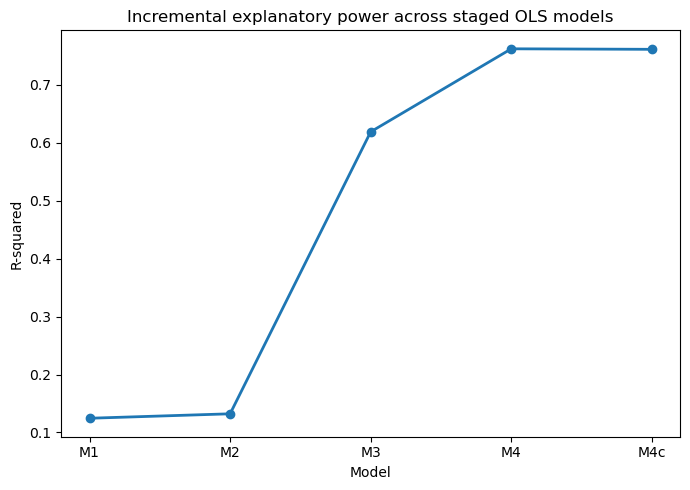

In [9]:
fit_plot_df = pd.DataFrame({
    "Model": ["M1", "M2", "M3", "M4", "M4c"],
    "R_squared": [
        float(ols_fit.loc[ols_fit["model"] == "ols_m1_controls_only", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m2_reputation", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m3_add_sentiment", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m4_full_text", "r_squared"].iloc[0]),
        float(revised_fit.loc[0, "r_squared"])
    ]
})

# Plot
plt.figure(figsize=(7, 5))
plt.plot(fit_plot_df["Model"], fit_plot_df["R_squared"], marker="o", linewidth=2)
plt.xlabel("Model")
plt.ylabel("R-squared")
plt.title("Incremental explanatory power across staged OLS models")
plt.tight_layout()

In [10]:
png_path = os.path.join(OUTPUT_DIR, "Figure2_incremental_model_fit.png")
pdf_path = os.path.join(OUTPUT_DIR, "Figure2_incremental_model_fit.pdf")
plt.savefig(png_path, dpi=300)
plt.savefig(pdf_path)
plt.close()

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
paper3_figures/Figure2_incremental_model_fit.png
paper3_figures/Figure2_incremental_model_fit.pdf


In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [12]:
M4_FILE = "paper3_stage5_regressions_finalfix/ols_m4_full_text.csv"
M4C_FILE = "paper3_stage3_revised_model/ols_m4c_validated_text_core.csv"
OUTPUT_DIR = "paper3_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [13]:
m4 = pd.read_csv(M4_FILE)
m4c = pd.read_csv(M4C_FILE)

In [14]:
terms_m4 = {
    "sentiment_continuous": "Sentiment polarity",
    "complaint_present": "Complaint language",
    "gratitude_present": "Appreciative language",
    "informativeness_win": "Informativeness"
}

terms_m4c = {
    "sentiment_continuous": "Sentiment polarity",
    "complaint_present": "Complaint language",
    "appreciative_language_present": "Appreciative language"
}

m4 = m4[m4["term"].isin(terms_m4.keys())].copy()
m4["label"] = m4["term"].map(terms_m4)
m4["model_name"] = "M4 Full text"

m4c = m4c[m4c["term"].isin(terms_m4c.keys())].copy()
m4c["label"] = m4c["term"].map(terms_m4c)
m4c["model_name"] = "M4c Validated core"

plot_df = pd.concat([m4, m4c], ignore_index=True)

In [15]:
order = ["Sentiment polarity", "Complaint language", "Appreciative language", "Informativeness"]
plot_df["label"] = pd.Categorical(plot_df["label"], categories=order, ordered=True)
plot_df = plot_df.sort_values(["label", "model_name"])

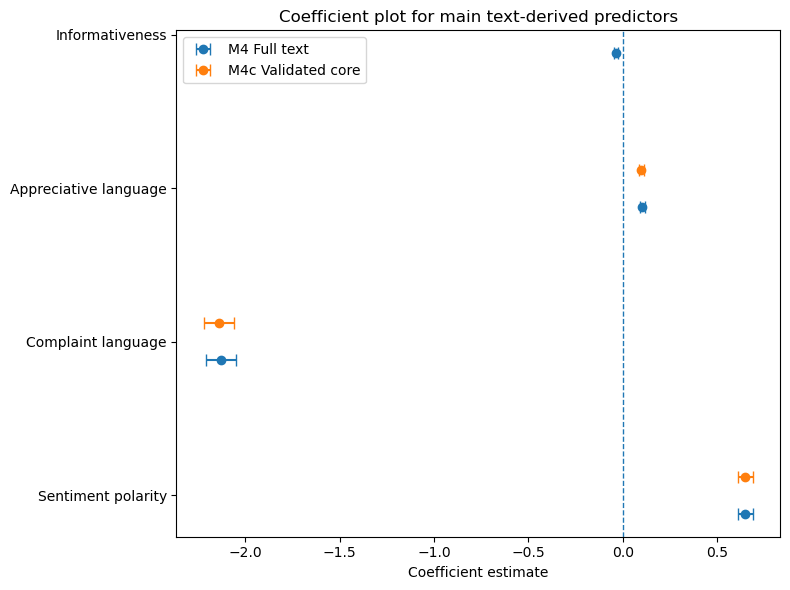

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

y_positions = np.arange(len(order))
offset = 0.12

for i, model_name in enumerate(["M4 Full text", "M4c Validated core"]):
    subset = plot_df[plot_df["model_name"] == model_name].copy()
    subset = subset.set_index("label").reindex(order).reset_index()

    # positions
    y = y_positions + (-offset if i == 0 else offset)

    # skip missing rows
    mask = subset["coef"].notna()
    ax.errorbar(
        subset.loc[mask, "coef"],
        y[mask],
        xerr=[
            subset.loc[mask, "coef"] - subset.loc[mask, "ci_low"],
            subset.loc[mask, "ci_high"] - subset.loc[mask, "coef"]
        ],
        fmt="o",
        capsize=4,
        label=model_name
    )

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(y_positions)
ax.set_yticklabels(order)
ax.set_xlabel("Coefficient estimate")
ax.set_title("Coefficient plot for main text-derived predictors")
ax.legend()
plt.tight_layout()

In [17]:
png_path = os.path.join(OUTPUT_DIR, "Figure3_coefficient_plot.png")
pdf_path = os.path.join(OUTPUT_DIR, "Figure3_coefficient_plot.pdf")
plt.savefig(png_path, dpi=300)
plt.savefig(pdf_path)
plt.close()

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
paper3_figures/Figure3_coefficient_plot.png
paper3_figures/Figure3_coefficient_plot.pdf


In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# File paths
M4_FILE = "paper3_stage5_regressions_finalfix/ols_m4_full_text.csv"
M4C_FILE = "paper3_stage3_revised_model/ols_m4c_validated_text_core.csv"
OUTPUT_DIR = "paper3_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load data
m4 = pd.read_csv(M4_FILE)
m4c = pd.read_csv(M4C_FILE)

# Keep focal predictors only
terms_m4 = {
    "sentiment_continuous": "Sentiment polarity",
    "complaint_present": "Complaint language",
    "gratitude_present": "Appreciative language",
    "informativeness_win": "Informativeness"
}

terms_m4c = {
    "sentiment_continuous": "Sentiment polarity",
    "complaint_present": "Complaint language",
    "appreciative_language_present": "Appreciative language"
}

m4 = m4[m4["term"].isin(terms_m4.keys())].copy()
m4["label"] = m4["term"].map(terms_m4)
m4["model_name"] = "M4 Full text"

m4c = m4c[m4c["term"].isin(terms_m4c.keys())].copy()
m4c["label"] = m4c["term"].map(terms_m4c)
m4c["model_name"] = "M4c Validated core"

plot_df = pd.concat([m4, m4c], ignore_index=True)

# Order
order = ["Sentiment polarity", "Complaint language", "Appreciative language", "Informativeness"]
plot_df["label"] = pd.Categorical(plot_df["label"], categories=order, ordered=True)
plot_df = plot_df.sort_values(["label", "model_name"])

# Build plot
fig, ax = plt.subplots(figsize=(8, 6))

y_positions = np.arange(len(order))
offset = 0.12

for i, model_name in enumerate(["M4 Full text", "M4c Validated core"]):
    subset = plot_df[plot_df["model_name"] == model_name].copy()
    subset = subset.set_index("label").reindex(order).reset_index()

    # positions
    y = y_positions + (-offset if i == 0 else offset)

    # skip missing rows
    mask = subset["coef"].notna()
    ax.errorbar(
        subset.loc[mask, "coef"],
        y[mask],
        xerr=[
            subset.loc[mask, "coef"] - subset.loc[mask, "ci_low"],
            subset.loc[mask, "ci_high"] - subset.loc[mask, "coef"]
        ],
        fmt="o",
        capsize=4,
        label=model_name
    )

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(y_positions)
ax.set_yticklabels(order)
ax.set_xlabel("Coefficient estimate")
ax.set_title("Coefficient plot for main text-derived predictors")
ax.legend()
plt.tight_layout()

# Save
png_path = os.path.join(OUTPUT_DIR, "Figure3_coefficient_plot.png")
pdf_path = os.path.join(OUTPUT_DIR, "Figure3_coefficient_plot.pdf")
plt.savefig(png_path, dpi=300)
plt.savefig(pdf_path)
plt.close()

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
paper3_figures/Figure3_coefficient_plot.png
paper3_figures/Figure3_coefficient_plot.pdf


In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# File paths
OLS_FIT_FILE = "paper3_stage5_regressions_finalfix/ols_model_fit_summary_finalfix.csv"
REVISED_FIT_FILE = "paper3_stage3_revised_model/paper3_revised_model_fit_summary.csv"
OUTPUT_DIR = "paper3_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load data
ols_fit = pd.read_csv(OLS_FIT_FILE)
revised_fit = pd.read_csv(REVISED_FIT_FILE)

# Build plot data
fit_plot_df = pd.DataFrame({
    "Model": ["M1", "M2", "M3", "M4", "M4c"],
    "R_squared": [
        float(ols_fit.loc[ols_fit["model"] == "ols_m1_controls_only", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m2_reputation", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m3_add_sentiment", "r_squared"].iloc[0]),
        float(ols_fit.loc[ols_fit["model"] == "ols_m4_full_text", "r_squared"].iloc[0]),
        float(revised_fit.loc[0, "r_squared"])
    ]
})

# Plot
plt.figure(figsize=(7, 5))
plt.plot(fit_plot_df["Model"], fit_plot_df["R_squared"], marker="o", linewidth=2)
plt.xlabel("Model")
plt.ylabel("R-squared")
plt.title("Incremental explanatory power across staged OLS models")
plt.tight_layout()

# Save
png_path = os.path.join(OUTPUT_DIR, "Figure2_incremental_model_fit.png")
pdf_path = os.path.join(OUTPUT_DIR, "Figure2_incremental_model_fit.pdf")
plt.savefig(png_path, dpi=300)
plt.savefig(pdf_path)
plt.close()

print("Saved:")
print(png_path)
print(pdf_path)

Saved:
paper3_figures/Figure2_incremental_model_fit.png
paper3_figures/Figure2_incremental_model_fit.pdf


In [1]:
import os
import re
import numpy as np
import pandas as pd

In [2]:
INPUT_FILE = "/Users/isaacasante/paper3_full_workflow_outputs/paper3_model_ready.csv"   # change to your final clean/model-ready file
OUTPUT_DIR = "paper3_github_repository"
SAMPLE_SIZE = 1000
RANDOM_STATE = 42

In [3]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
for folder in ["data", "scripts", "notebooks", "outputs/tables", "outputs/figures", "docs"]:
    os.makedirs(os.path.join(OUTPUT_DIR, folder), exist_ok=True)

In [4]:
df = pd.read_csv(INPUT_FILE)
print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

/var/folders/hx/wmtrx35177n537rlc2k5_t100000gn/T/ipykernel_50294/3214340132.py:1: DtypeWarning: Columns (0,1,2,3,5,6,7,12,16,17,18,19,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(INPUT_FILE)


Original shape: (1048575, 33)
Columns: ['review_id', 'doctor_id', 'doctor_gender', 'doctor_title', 'doctor_title_num', 'department', 'province', 'city', 'review_count', 'patient_count', 'log_review_count', 'log_patient_count', 'review_time', 'review_year', 'review_month', 'review_quarter', 'review_type', 'review_symptom', 'review_tags', 'review_text', 'rating', 'review_length', 'tag_count', 'symptom_present', 'complaint_present', 'gratitude_present', 'detail_keyword_count', 'question_mark_count', 'informativeness', 'sentiment_label_raw', 'sentiment_score_raw', 'sentiment_continuous', 'sentiment_polarity']


In [5]:
safe_columns = [
    "rating",
    "review_text_clean",
    "sentiment_continuous",
    "complaint_present",
    "appreciative_language_present",
    "informativeness",
    "log_review_count",
    "log_patient_count",
    "doctor_title_num",
    "review_length",
    "tag_count",
    "symptom_present",
    "review_year"
]
if "appreciative_language_present" not in df.columns and "gratitude_present" in df.columns:
    df["appreciative_language_present"] = df["gratitude_present"]

In [6]:
safe_columns_existing = [c for c in safe_columns if c in df.columns]
sample_df = df[safe_columns_existing].copy()

In [7]:
def deidentify_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    # Remove phone numbers
    text = re.sub(r"\b1[3-9]\d{9}\b", "[PHONE]", text)
    text = re.sub(r"\b\d{3,4}[-\s]?\d{7,8}\b", "[PHONE]", text)
    # Remove emails
    text = re.sub(r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}", "[EMAIL]", text)
    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "[URL]", text)
    # Mask common Chinese hospital/institution name patterns
    text = re.sub(r"[\u4e00-\u9fff]{2,30}(医院|卫生院|诊所|医学院|大学附属医院|妇幼保健院)", "[INSTITUTION]", text)
    # Mask possible Chinese personal-name-like mentions after doctor/Dr labels
    text = re.sub(r"(医生|大夫|主任|教授)[\u4e00-\u9fff]{1,3}", r"\1[NAME]", text)
    # Remove excessive whitespace
    text = re.sub(r"\s+", " ", text).strip()
    return text
if "review_text_clean" in sample_df.columns:
    sample_df["review_text_clean"] = sample_df["review_text_clean"].apply(deidentify_text)

In [8]:
if "review_text_clean" in sample_df.columns:
    sample_df = sample_df[sample_df["review_text_clean"].str.len() > 0].copy()

In [9]:
if "rating" in sample_df.columns:
    sample_public = (
        sample_df
        .groupby("rating", group_keys=False)
        .apply(lambda x: x.sample(
            n=min(len(x), max(1, int(SAMPLE_SIZE * len(x) / len(sample_df)))),
            random_state=RANDOM_STATE
        ))
        .sample(frac=1, random_state=RANDOM_STATE)
        .reset_index(drop=True)
    )
    # If rounding gives fewer rows, top up randomly
    if len(sample_public) < SAMPLE_SIZE:
        remaining = sample_df.drop(sample_public.index, errors="ignore")
        add_n = min(SAMPLE_SIZE - len(sample_public), len(remaining))
        if add_n > 0:
            extra = remaining.sample(n=add_n, random_state=RANDOM_STATE)
            sample_public = pd.concat([sample_public, extra], ignore_index=True)
else:
    sample_public = sample_df.sample(
        n=min(SAMPLE_SIZE, len(sample_df)),
        random_state=RANDOM_STATE
    ).reset_index(drop=True)

/var/folders/hx/wmtrx35177n537rlc2k5_t100000gn/T/ipykernel_50294/1293325332.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_df


In [10]:
risky_patterns = [
    "name", "doctor_name", "hospital", "nickname", "reviewer",
    "id", "uuid", "profile", "bio", "introduction", "city", "province"
]
for col in list(sample_public.columns):
    if any(p.lower() in col.lower() for p in risky_patterns):
        sample_public.drop(columns=[col], inplace=True)

In [11]:
sample_path = os.path.join(OUTPUT_DIR, "data", "sample_reviews_deidentified.csv")
sample_public.to_csv(sample_path, index=False, encoding="utf-8-sig")
print("Saved sample dataset:", sample_path)
print("Sample shape:", sample_public.shape)

Saved sample dataset: paper3_github_repository/data/sample_reviews_deidentified.csv
Sample shape: (1000, 12)


In [12]:
variable_dictionary = pd.DataFrame([
    {
        "variable": "rating",
        "description": "Patient rating outcome from the online healthcare platform.",
        "type": "numeric",
        "role": "dependent variable"
    },
    {
        "variable": "review_text_clean",
        "description": "De-identified patient review text used for text analytics.",
        "type": "text",
        "role": "text source"
    },
    {
        "variable": "sentiment_continuous",
        "description": "Transformer-derived sentiment polarity score.",
        "type": "numeric",
        "role": "primary text-derived predictor"
    },
    {
        "variable": "complaint_present",
        "description": "Binary indicator for explicit complaint or dissatisfaction language.",
        "type": "binary",
        "role": "primary text-derived predictor"
    },
    {
        "variable": "appreciative_language_present",
        "description": "Binary indicator for praise, appreciation, or favorable evaluative wording.",
        "type": "binary",
        "role": "primary text-derived predictor"
    },
    {
        "variable": "informativeness",
        "description": "Standardized exploratory proxy for decision-useful review detail.",
        "type": "numeric",
        "role": "secondary exploratory predictor"
    },
    {
        "variable": "log_review_count",
        "description": "Log-transformed physician review count.",
        "type": "numeric",
        "role": "structured reputation signal"
    },
    {
        "variable": "log_patient_count",
        "description": "Log-transformed physician patient count.",
        "type": "numeric",
        "role": "structured reputation signal"
    },
    {
        "variable": "doctor_title_num",
        "description": "Ordered coding of physician professional title.",
        "type": "ordinal numeric",
        "role": "structured physician signal"
    },
    {
        "variable": "review_length",
        "description": "Character length of the cleaned review text.",
        "type": "numeric",
        "role": "auxiliary text variable"
    },
    {
        "variable": "tag_count",
        "description": "Number of review tags associated with the review.",
        "type": "numeric",
        "role": "auxiliary text variable"
    },
    {
        "variable": "symptom_present",
        "description": "Binary indicator for whether a symptom field was present.",
        "type": "binary",
        "role": "auxiliary text variable"
    },
    {
        "variable": "review_year",
        "description": "Year extracted from the review timestamp.",
        "type": "numeric",
        "role": "temporal control"
    }
])
variable_dictionary = variable_dictionary[
    variable_dictionary["variable"].isin(sample_public.columns)
]
dict_path = os.path.join(OUTPUT_DIR, "data", "variable_dictionary.csv")
variable_dictionary.to_csv(dict_path, index=False, encoding="utf-8-sig")
print("Saved variable dictionary:", dict_path)

Saved variable dictionary: paper3_github_repository/data/variable_dictionary.csv


In [13]:
readme_text = """# Patient Narratives as eWOM on Online Healthcare Platforms
This repository contains code, sample data, and reproducibility materials for the manuscript:
**Do patient narratives function as electronic word-of-mouth? Textual review signals and ratings on an online healthcare platform**
## Repository contents
- `data/`: de-identified sample dataset and variable dictionary
- `scripts/`: scripts used for cleaning, variable construction, validation, regression, and figure/table generation
- `notebooks/`: optional Jupyter notebooks for the workflow
- `outputs/`: generated tables and figures
- `docs/`: methodological notes and data documentation
## Data availability
The complete dataset cannot be publicly shared due to platform and privacy considerations.  
A fully de-identified sample dataset is provided for reproducibility demonstration purposes.
## Workflow
The analysis follows these steps:
1. Data cleaning and de-identification
2. Variable construction
3. NLP-derived construct validation
4. Descriptive statistics
5. Staged regression models
6. Robustness checks
7. Table and figure generation
## Software
The analysis was conducted in Python. Required packages are listed in `requirements.txt`.
## Citation
Please cite the manuscript if using this repository.
"""
readme_path = os.path.join(OUTPUT_DIR, "README.md")
with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_text)
print("Saved README:", readme_path)

Saved README: paper3_github_repository/README.md


In [14]:
requirements_text = """pandas
numpy
scikit-learn
statsmodels
matplotlib
transformers
torch
jieba
openpyxl
"""
requirements_path = os.path.join(OUTPUT_DIR, "requirements.txt")
with open(requirements_path, "w", encoding="utf-8") as f:
    f.write(requirements_text)
print("Saved requirements:", requirements_path)

Saved requirements: paper3_github_repository/requirements.txt


In [15]:
gitignore_text = """# Python
__pycache__/
*.pyc
.ipynb_checkpoints/
# Data not for public upload
data/raw/
data/full/
*.xlsx
*.xls
# System files
.DS_Store
# Large model files
models/
*.bin
*.pt
*.pth
"""
gitignore_path = os.path.join(OUTPUT_DIR, ".gitignore")
with open(gitignore_path, "w", encoding="utf-8") as f:
    f.write(gitignore_text)
print("Saved .gitignore:", gitignore_path)

Saved .gitignore: paper3_github_repository/.gitignore


In [16]:
script_files = {
    "01_data_cleaning.py": "# Data cleaning and de-identification script\n",
    "02_variable_construction.py": "# Variable construction script\n",
    "03_validation_analysis.py": "# Human validation and NLP validation script\n",
    "04_regression_models.py": "# Regression and robustness models script\n",
    "05_tables_figures.py": "# Table and figure generation script\n"
}
for filename, content in script_files.items():
    path = os.path.join(OUTPUT_DIR, "scripts", filename)
    with open(path, "w", encoding="utf-8") as f:
        f.write(content)
print("Created script placeholder files.")

Created script placeholder files.


In [17]:
print("\nGitHub-ready folder created:")
print(OUTPUT_DIR)
print("\nRecommended upload folder contents:")
for root, dirs, files in os.walk(OUTPUT_DIR):
    level = root.replace(OUTPUT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files:
        print(f"{indent}  {file}")


GitHub-ready folder created:
paper3_github_repository

Recommended upload folder contents:
paper3_github_repository/
  requirements.txt
  README.md
  .gitignore
  docs/
  scripts/
    05_tables_figures.py
    01_data_cleaning.py
    02_variable_construction.py
    04_regression_models.py
    03_validation_analysis.py
  data/
    variable_dictionary.csv
    sample_reviews_deidentified.csv
  outputs/
    tables/
    figures/
  notebooks/
